In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from time import sleep

import qcodes
from qcodes import Instrument, Parameter
from qcodes.parameters import DelegateParameter, ScaledParameter
from qcodes.instrument_drivers.IST_devices.FastDuck import FastDuck

import pyvisa

import json 
import sys

from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit

from scripts.auto_tuning import *
from scripts.score_function import *

# Import instruments


## IVVI

In [5]:
# FAST DUCK
DAC = FastDuck('DAC','COM3', dac_step=10.0, dac_delay=.50)
station = qcodes.Station(DAC)

Vdot_scaled = DelegateParameter("Vdot", DAC.dac2, scale = 100)
Vsensor_scaled = DelegateParameter("Vsensor", DAC.dac3, scale = 100)
Backbone = DelegateParameter("Backbone", DAC.dac4)

SL = DelegateParameter("SL", DAC.dac6, label='SL')
SP = DelegateParameter("SP", DAC.dac7, label='SP')
SR = DelegateParameter("SR", DAC.dac8, label='SR')
BL = DelegateParameter("BL", DAC.dac9, label='BL')
PL = DelegateParameter("PL", DAC.dac10, label='PL')
B12 = DelegateParameter("B12", DAC.dac11, label='B12')
PM = DelegateParameter("PM", DAC.dac12, label='PM')
B23 = DelegateParameter("B23", DAC.dac13, label='B23')
PR = DelegateParameter("PR", DAC.dac14)
BR = DelegateParameter("BR", DAC.dac15)

list_gates = [Vdot_scaled, Vsensor_scaled, Backbone, SL, SP, SR, BL, PL, B12, PM, B23, PR, BR]
for gate_VParam in list_gates:
    station.add_component(gate_VParam)

#Setting min and max values for each DAC
DAC.parameters['dac1'].vals._min_value = 0.0
DAC.parameters['dac1'].vals._max_value = 1010.0

DAC.parameters['dac2'].vals._min_value = -20.0 #Ftransi-10.0
DAC.parameters['dac2'].vals._max_value = 20.0 # 10.0
DAC.parameters['dac3'].vals._min_value = -700.0 #-10.0
DAC.parameters['dac3'].vals._max_value = 700.0 #10.0

DAC.parameters['dac4'].vals._min_value = 2608.0 #0.0
DAC.parameters['dac4'].vals._max_value = 2610.0 #4000.0

DAC.parameters['dac5'].vals._min_value = 0.0 #0.0
DAC.parameters['dac5'].vals._max_value = 20.0 #4000.0

# SL
DAC.parameters['dac6'].vals._min_value = 750.0 #0.0
DAC.parameters['dac6'].vals._max_value = 950.0 #4000.0

# SP
DAC.parameters['dac7'].vals._min_value = 2000.0 #0.0
DAC.parameters['dac7'].vals._max_value = 3000.0 #4000.0

# SR
DAC.parameters['dac8'].vals._min_value = 750.0 #0.0
DAC.parameters['dac8'].vals._max_value = 950.0 #4000.0

# BL
DAC.parameters['dac9'].vals._min_value = 1340.0 #0.0
DAC.parameters['dac9'].vals._max_value = 1740.0 #4000.0

# PL
DAC.parameters['dac10'].vals._min_value = 1000.0 #0.0
DAC.parameters['dac10'].vals._max_value = 2600.0

# B12
DAC.parameters['dac11'].vals._min_value = 400.0
DAC.parameters['dac11'].vals._max_value = 800.0

# PM
DAC.parameters['dac12'].vals._min_value = 1350.0
DAC.parameters['dac12'].vals._max_value = 2950.0

# B23
DAC.parameters['dac13'].vals._min_value = 300.0
DAC.parameters['dac13'].vals._max_value = 640.0

# PR
DAC.parameters['dac14'].vals._min_value = -1.0
DAC.parameters['dac14'].vals._max_value = 3000.0

# BR
DAC.parameters['dac15'].vals._min_value = -1.0
DAC.parameters['dac15'].vals._max_value = 3000.0

DAC.parameters['dac16'].vals._min_value = -1.0
DAC.parameters['dac16'].vals._max_value = 1.0

DAC.dac9.step = 30.0
DAC.dac9.inter_delay=0.0
DAC.dac10.step = 30.0
DAC.dac10.inter_delay=0.0
DAC.dac12.step = 30.0
DAC.dac12.inter_delay=0.0

## OPX

In [1]:

###OPX#####
from qm.qua import *
from qm import QuantumMachinesManager
from qm import SimulationConfig
from opx_files.configuration import *
from opx_files.macros import RF_reflectometry_macro, get_filtered_voltage
from opx_files.measurement_helpers import *

from qualang_tools.external_frameworks.qcodes.opx_driver import OPX # to use dond function of qcodes
from qualang_tools.loops import from_array
from qualang_tools.results import progress_counter, fetching_tool, wait_until_job_is_paused
from qualang_tools.plot import interrupt_on_close
from qualang_tools.addons.variables import assign_variables_to_element
from qualang_tools.units import unit
u = unit(coerce_to_integer=True)

import logging

2025-03-14 11:46:22,154 - qm - INFO     - Starting session: a008043d-978a-4741-a61e-5174ef1b9c84


In [4]:
qmm = QuantumMachinesManager(host=qop_ip, port=qop_port, cluster_name=cluster_name)

# Set logging level to WARNING to hide INFO messages
logging.getLogger('qm').setLevel(logging.WARNING)

2025-03-14 11:50:31,580 - qm - INFO     - Performing health check
2025-03-14 11:50:31,592 - qm - INFO     - Health check passed


## Magnet

In [13]:
from qcodes.instrument_drivers.american_magnetics.AMI430 import AMI430
B_outplane = AMI430('B_outplane', address = '10.21.64.65', port=7180)
B_inplane = AMI430('B_inplane', address = '10.21.64.64', port=7180)
B_outplane.ramp_rate.set(0.0004) #T/s

B_outplane.field_limit.set(21e-3)
B_inplane.field_limit.set(50e-3)

station.add_component(B_outplane)
station.add_component(B_inplane)

Connected to: AMERICAN MAGNETICS INC. 430 (serial:150018, firmware:2.59) in 1.12s
Connected to: AMERICAN MAGNETICS INC. 430 (serial:150017, firmware:2.59) in 1.26s


'B_inplane'

# Create database

In [25]:
## Multidimensional scanning module
from qcodes.dataset import (
    LinSweep,
    LogSweep,
    Measurement,
    TogetherSweep,
    do1d,
    do2d,
    dond,
    experiments,
    initialise_or_create_database_at,
    load_by_run_spec,
    load_or_create_experiment,
    plot_dataset,
)

initialise_or_create_database_at(r"Data\Autonomous_Run.db")

# Functions

## Helpers for saving

In [16]:
def save_1Dplot_in_qcodes(x, z_list, config=None, exp=None, station=None, x_param=None):
    '''
    Save multiple 1D datasets in qcodes.

    Parameters:
    x : array-like
        The x-axis values (independent parameter).
    z_list : list of array-like
        A list of 1D arrays corresponding to different measured parameters.
    config : dict, optional
        Config file of OPX (can be used to save metadata).
    exp : Experiment object, optional
        The qcodes experiment object.
    station : Station object, optional
        The qcodes station object.
    '''
    
    # Create a Measurement object
    meas = Measurement(exp=exp, station=station)
   
    # Register x as an independent parameter
    if x_param==None:
        x_param = qcodes.Parameter('x', label='X-axis', unit='a.u.', set_cmd=None, get_cmd=None)
    meas.register_parameter(x_param)
    
    # Create a list to store the z parameters (dependent parameters)
    z_params = []
    
    # Loop over z_list and register each z as a dependent parameter with x as the setpoint
    for idx, z in enumerate(z_list):
        z_param = qcodes.Parameter(f'z_{idx}', label=f'Z-value {idx+1}', unit='a.u.', set_cmd=None, get_cmd=None)
        meas.register_parameter(z_param, setpoints=(x_param,))
        z_params.append(z_param)
    
    # Start the measurement
    with meas.run() as datasaver:
        # Loop over the values of x and z arrays
        results = [(x_param, x)]
        for idx, z_param in enumerate(z_params):
            results.append((z_param, z_list[idx]))
        datasaver.add_result(*results)
        
        dataset = datasaver.dataset  # This will allow you to retrieve the dataset later

    # Add metadata to the dataset after the measurement
    if config:
        # Convert the config dictionary to a JSON string
        dataset.add_metadata("config_OPX", json.dumps(config))
        
    # print(f"Data saved in dataset with ID: {dataset.run_id}")

    return dataset



def save_2Dplot_in_qcodes(x, y, z_list, config=None, exp=None, station=None, x_param = None, y_param = None):
    '''
    Save multiple 2D datasets in qcodes.

    Parameters:
    x : array-like
        The x-axis values (independent parameter).
    y : array-like
        The y-axis values (independent parameter).
    config : dict
        Config file of OPX
    z_list : list of array-like
        A list of 2D arrays corresponding to different measured parameters.
    exp : Experiment object, optional
        The qcodes experiment object.
    station : Station object, optional
        The qcodes station object.
    '''
    
    # Create a Measurement object
    meas = Measurement(exp=exp, station=station)
    
    # Register x and y as independent parameters
    if x_param==None:
        x_param = qcodes.Parameter('x', label='X-axis', unit='a.u.', set_cmd=None, get_cmd=None)
    if y_param==None:
        y_param = qcodes.Parameter('y', label='Y-axis', unit='a.u.', set_cmd=None, get_cmd=None)
    
    # Register x and y as independent parameters in the measurement
    meas.register_parameter(x_param)
    meas.register_parameter(y_param)
    
    # Create a list to store the z parameters (dependent parameters)
    z_params = []
    
    # Loop over z_list and register each z as a dependent parameter with x and y as setpoints
    for idx, z in enumerate(z_list):
        z_param = qcodes.Parameter(f'z_{idx}', label=f'Z-value {idx+1}', unit='a.u.', set_cmd=None, get_cmd=None)
        meas.register_parameter(z_param, setpoints=(x_param, y_param))
        z_params.append(z_param)
    
    # Start the measurement
    
    with meas.run() as datasaver:
        for idx, z_param in enumerate(z_params):
            results =[(x_param, np.reshape(np.tile(x, len(y)), (z_list[idx].shape))), (y_param, np.reshape(np.repeat(y, len(x)), (z_list[idx].shape))), (z_param, z_list[idx])]
            # results =[(x_param, np.reshape(np.tile(x, len(y)), (z_list[idx].shape))), (y_param, np.reshape(np.repeat(y, len(x)), (z_list[idx].T.shape))), (z_param, z_list[idx])]
            datasaver.add_result(*results)
                  
    dataset = datasaver.dataset  # This will allow you to retrieve the dataset later

    # Add metadata to the dataset after the measurement
    if config:
        # Convert the config dictionary to a JSON string
        dataset.add_metadata("config_OPX", json.dumps(config))
        
    # print(f"Data saved in dataset with ID: {dataset.run_id}")

    return dataset


## Algorithm Functions

In [18]:
from scipy.signal import savgol_filter, find_peaks
from scipy.stats import qmc, norm
from scipy.spatial.distance import cdist
from matplotlib.colors import SymLogNorm
import matplotlib.colors as mcolors
from matplotlib.patches import Circle, Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

cmap = 'YlGnBu'
from tqdm import tqdm


def get_interdot_location(x_middle_phys, y_middle_phys, scan_size_mV):

    scan_size_OPX_V = mV_2_opx_V(scan_size_mV)
    resolution = 100
    resolution_x = 103  # will be clipped
    resolution_y = 100
    n_avg = 10
    change_readout_time(25000)
    change_readout_amp(0.02)

    scan_params = (x_middle_phys, y_middle_phys, scan_size_mV, resolution)

    offset_slow = config['controllers']['con1']['analog_outputs'][2]['offset']
    offset_fast = config['controllers']['con1']['analog_outputs'][1]['offset']
    voltage_values_slow = generate_slow_axis_points(scan_size_OPX_V, resolution_y) + offset_slow
    voltage_values_fast = np.linspace(-(1.03*scan_size_OPX_V)/2, scan_size_OPX_V/2, resolution_x) + offset_fast

    x_dac = np.linspace(x_middle_phys-scan_size_mV/2, x_middle_phys+scan_size_mV/2, resolution)  # for saving and plotting purposes
    y_dac = np.linspace(y_middle_phys-scan_size_mV/2, y_middle_phys+scan_size_mV/2, resolution)

    with program() as fast_charge_stability_prog:
        n, n_st= declare(int), declare_stream()
        Vfast, Vfast_st = declare(fixed), declare_stream()
        Vslow, Vslow_st = declare(fixed), declare_stream()

        with for_(n, 0, n < n_avg, n + 1):  # The averaging loop
            with for_each_(Vslow, voltage_values_slow): # allows arbitrary increments, y axis
                with for_(*from_array(Vfast, voltage_values_fast)): # allows ONLY linear or log increments, x axis
                    set_dc_offset("PL", "single", Vfast)
                    set_dc_offset("PM", "single", Vslow)
                    wait(40 * u.us)  # this is super long, but needed to settle to reduce lead latching
                    reset_phase("tank_circuit")
                    I, Q, I_st, Q_st = RF_reflectometry_macro()
                    wait(1 * u.us)  # if insufficient, pulsing back in fast loop interferres with readout
            set_dc_offset("PL", "single", offset_fast)  # Return elements to starting offsets at the beginning of the next average
            set_dc_offset("PM", "single", offset_slow)
            save(n, n_st)

        with stream_processing():
            n_st.save("iteration")
            I_st.buffer(resolution_x).buffer(resolution_y).buffer(n_avg).map(FUNCTIONS.average()).save_all("I")
            Q_st.buffer(resolution_x).buffer(resolution_y).buffer(n_avg).map(FUNCTIONS.average()).save_all("Q")

    qm = qmm.open_qm(config)
    job = qm.execute(fast_charge_stability_prog)
    results = fetching_tool(job, data_list=["I", "Q", "iteration"])
    I, Q, iteration = results.fetch_all()
    data_I, data_Q = unscramble_slow_axis(I[0]), unscramble_slow_axis(Q[0])
    S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
    R_rf = np.abs(S)[:, 3:]  # Amplitude
    phase_rf = np.angle(S)[:, 3:]  # Phase

    run_id = None
    if save2db:
        experiment = load_or_create_experiment(experiment_name="virtualisation_diag_fast_Interdot_{}".format(interdot_number), sample_name="10721_S47")
        dataset = save_2Dplot_in_qcodes(x_dac, y_dac, [R_rf, phase_rf], config=config, exp=experiment, station=station, x_param=PL, y_param=PM)
        run_id = dataset.run_id

    line_image, quality_score, vertex_coords, triangle_coords, interdot_midpoint = get_metastable_vertices(R_rf, scan_params)

    return R_rf, line_image, quality_score, vertex_coords, triangle_coords, interdot_midpoint


def check_for_IDT():
    # re-center interdot
    window_size = window_sizes[interdot_number]
    dist2center = window_sizes[interdot_number]
    interdot_length = window_sizes[interdot_number]
    x_middle_phys = PL()
    y_middle_phys = PM()
    adjustments = 0
    while ((dist2center > (0.15 * window_size)) or (interdot_length < (window_size / 6))) and adjustments < 3:  # does not need to be as zoomed in for virtualisation
        print('Recentering and measuring scan')
        
        R_rf, line_image, quality_score, vertex_coords, triangle_coords, interdot_midpoint = get_interdot_location(x_middle_phys, y_middle_phys, window_size)

        dist2center = np.sqrt((x_middle_phys-interdot_midpoint[0])**2 + (y_middle_phys-interdot_midpoint[1])**2)
        interdot_length = np.sqrt((vertex_coords[0][0] - vertex_coords[2][0])**2 + (vertex_coords[0][1] - vertex_coords[2][1])**2)
        window_size = 6.5 * interdot_length  # reduce window size
        
        virts_sensor.vPL(interdot_midpoint[0])
        virts_sensor.vPM(interdot_midpoint[1])
        x_middle_phys = PL()
        y_middle_phys = PM()
        
        adjustments += 1

    return quality_score, x_middle_phys, y_middle_phys, window_size


def virtualise_barriers(interdot_number, virts):

    fine_tune_sensor(plot=True)

    # first attempt to find IDT
    quality_score, x_middle_phys, y_middle_phys, window_size = check_for_IDT()

    # second attempt
    if quality_score < 1:
        print('Re-attempting to find IDT!')
        # Re-attempt to find IDT by increasing middle barrier
        current_voltage = virts.vB12() 
        virts.vB12(current_voltage + window_size/6) # New voltage 
        fine_tune_sensor()
        quality_score, x_middle_phys, y_middle_phys, window_size = check_for_IDT()

        # third attempt
        if quality_score < 1:
            #Re-attemtping to find IDT by dereasing middle barrier
            current_voltage = virts.vB12() 
            virts.vB12(current_voltage - window_size/3) # New voltage 
            fine_tune_sensor()
            quality_score, x_middle_phys, y_middle_phys, window_size = check_for_IDT()

            # failure
            if quality_score < 1:
                print('Interdot {interdot_number} not found in window (after 3 attemps)!')
                return False       

    fine_tune_sensor()
    R_rf0, _, _, _, triangle_coords0, interdot_midpoint0 = get_interdot_location(x_middle_phys, y_middle_phys, window_size)
    x_dac = np.linspace(x_middle_phys-window_size/2, x_middle_phys+window_size/2, 100)
    y_dac = np.linspace(y_middle_phys-window_size/2, y_middle_phys+window_size/2, 100)

    print('Virtualising barriers...')
    # collect at two steps on each barrier, the size is determined by the interdot length
    dPL, dPM, mPL, mPM, cPL, cPM, c_matrix = np.zeros((3, 3)), np.zeros((3,3)), np.zeros(3), np.zeros(3), np.zeros(3), np.zeros(3), np.zeros((2, 3))
    diagrams, vertices, midpoints = [], [], []
    gates = [BL, B12, B23]
    steps = [-window_size/8, 0, window_size/8]
    
    for i, gate in enumerate(gates):
        gate_start = gate()
        diagram_set, coords_set, midpoint_set = [], [], []
        
        for step in steps:
            if step == 1:
                diagram_set.append(R_rf0)
                coords_set.append(triangle_coords0)
                diagram_set.append(interdot_midpoint0)
            else:
                gate(gate() + step)
                R_rf, _, _, _, triangle_coords, interdot_midpoint = get_interdot_location(x_middle_phys, y_middle_phys, window_size)
                gate(gate_start)
                diagram_set.append(R_rf)
                coords_set.append(triangle_coords)
                midpoint_set.append(interdot_midpoint)  

        dPL[i, :], dPM[i, :] = np.array(midpoint_set)[:, 0] - x_middle_phys, np.array(midpoint_set)[:, 1] - y_middle_phys 
        mPL[i], cPL[i] = np.polyfit(steps, dPL[i], 1)
        mPM[i], cPM[i] = np.polyfit(steps, dPM[i], 1)
        c_matrix[0, i], c_matrix[1, i] = -mPL[i], -mPM[i] 
        
        diagrams.append(diagram_set)
        vertices.append(coords_set)
        midpoints.append(midpoint_set)
    
    # initialise and update virtualisation matrix
    vgate_list = ["vBL", "vPL", "vB12", "vPM", "vB23", "vSP"]
    dac_list =  [DAC.dac9.name, DAC.dac10.name, DAC.dac11.name, DAC.dac12.name, DAC.dac13.name, DAC.dac7.name]
    c = virts_sensor.convert_map_to_matrix(virts_sensor.get_crosscap_map())
    c[1, 0], c[1, 2], c[1, 4] = c_matrix[0, 0], c_matrix[0, 1], c_matrix[0, 2]
    c[3, 0], c[3, 2], c[3, 4] = c_matrix[1, 0], c_matrix[1, 1], c_matrix[1, 2]
    try:
        crosscap_map = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c)
        virts = VG.VirtualGates("VGates", DAC, crosscap_map)
    except:
        try:
            crosscap_map = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c)
            virts.set_crosscap_map(crosscap_map)
        except:
            if "VGates" in VG.VirtualGates._all_instruments:
                del VG.VirtualGates._all_instruments["VGates"]
            crosscap_map = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c)
            virts = VG.VirtualGates("VGates", DAC, crosscap_map)  
    virts.print_matrix()

    c_matrices.append(c_matrix)

    # plot results
    fig, axs = plt.subplots(3, 3, figsize=(9, 6))
    for g, (diagram_set, coords_set, midpoint_set) in enumerate(zip(diagrams, vertices, midpoints)):
        for s, (stability_diagram, triangle_coords) in enumerate(zip(diagram_set, coords_set)):
            axs[g,s].set_title(f'{str(gates[g])}: {steps[s]:.3f}')
            cax = axs[g,s].pcolormesh(x_dac, y_dac, stability_diagram*1e6, cmap=cmap)
            fig.colorbar(cax, ax=axs[g,s], fraction=0.045, pad=0.05)
            axs[g,s].plot(*triangle_coords.T, ls=':', lw=2, c='w')
            axs[g,s].plot(*np.array(midpoint_set).T, ls='-', lw='2', c='r', marker='o', markersize=5)
            axs[g,s].set_xlabel('PL (mV)')
            axs[g,s].set_ylabel('PM (mV)')
            axs[g,s].set_aspect('equal')
    fig.suptitle(f'Interdot {interdot_number}')
    plt.tight_layout()
    plt.show()
    
    fig, axs = plt.subplots(1, 2, figsize=(7, 3))
    axs[0].set_title('PL Cross-Capacitance')
    axs[1].set_title('PM Cross-Capacitance')
    for i, gate in enumerate(gates):
        axs[0].scatter(steps, dPL[i], s=30, label=f'{gate}, c={c_matrix[0, i]:.3f}')
        axs[1].scatter(steps, dPM[i], s=30, label=f'{gate}, c={c_matrix[1, i]:.3f}')
        axs[0].plot(steps, np.array(mPL[i])*steps + cPL[i], lw=2)
        axs[1].plot(steps, np.array(mPM[i])*steps + cPM[i], lw=2)
    axs[0].set_xlabel(r'$\Delta V_i$ (mV)')
    axs[1].set_xlabel(r'$\Delta V_i$ (mV)')
    axs[0].set_ylabel(r'$\Delta PL$ (mV)')
    axs[1].set_ylabel(r'$\Delta PM$ (mV)')
    axs[0].legend(frameon=False, fontsize=8)
    axs[1].legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

    return True


def fine_tune_sensor(plot=False):
    init_sensor = SP()
    scan_half_range = 10  # in mV
    n_points = 150
    n_avg = 100
    t_buffer = 160
    start = init_sensor - scan_half_range
    stop = init_sensor + scan_half_range
    dac_points = np.linspace(start, stop, n_points)
    change_readout_time(25000)
    change_readout_amp(0.02)
    
    with program() as sensor_plunger_1d:
        p, p_st = declare(int), declare_stream()
        n, n_st = declare(int), declare_stream()
        
        with for_(p, 0, p < n_points, p + 1):  # The DAC step loop
            pause()
            with for_(n, 0, n < n_avg, n + 1):  # The averaging loop
                reset_phase("tank_circuit")
                I, Q, I_st, Q_st = RF_reflectometry_macro()
                wait(t_buffer)
                save(n, n_st)
            save(p, p_st)
    
        with stream_processing():
            p_st.save('DAC_val')
            n_st.save("iteration")
            I_st.buffer(n_avg).map(FUNCTIONS.average()).buffer(n_points).save_all("I")
            Q_st.buffer(n_avg).map(FUNCTIONS.average()).buffer(n_points).save_all("Q")
    
    qm = qmm.open_qm(config)
    job = qm.execute(sensor_plunger_1d)
    for i, voltage in enumerate((dac_points)):
        wait_until_job_is_paused(job)
        SP(voltage)
        sleep(1e-3)
        job.resume()
    
    SP(init_sensor)  # return sensor to mid_point after sweep
    
    results = fetching_tool(job, data_list=["I", "Q", "iteration", 'DAC_val'])
    I, Q, iteration, DAC_val = results.fetch_all()
    data_I, data_Q = I[0], Q[0]
    S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
    R, phase = np.abs(S), np.angle(S)  # Amplitude and Phase
    
    # smooth data and gradient
    smoothed_R = savgol_filter(R, window_length=n_points//10, polyorder=3)
    dR = np.gradient(smoothed_R)
    smoothed_dR = savgol_filter(dR, window_length=n_points//5, polyorder=3)

    # find coulomb peak and find steepest flank on same side 
    peaks, _ = find_peaks(smoothed_R, height=(max(R) - min(R))/2, distance=n_points)
    if len(peaks) != 0:
        peak_idx = peaks[0]
        peak_mV = dac_points[peak_idx]
    
        if peak_mV < init_sensor:  # find steepest slope on right flank
            steepest_idx = np.argmax(np.abs(smoothed_dR[peak_idx:])) + peak_idx
        elif peak_mV > init_sensor:  # find steepest slope on left flank
            steepest_idx = np.argmax(np.abs(smoothed_dR[:peak_idx]))
            
    else: # if no peak found, just take steepest point
        steepest_idx = np.argmax(np.abs(smoothed_dR))
    
    steepest_mV = dac_points[steepest_idx]
    SP(steepest_mV)

    print(f'New sensing point set to {steepest_mV:.2f} mV, a change of {(steepest_mV - init_sensor):.2f} mV from before')

    if plot:
        ## Display adjustments
        fig, ax1 = plt.subplots(figsize=(5, 2))
        ax1.scatter(dac_points, R*1e6, color='b', s=2, zorder=2)
        ax1.plot(dac_points, smoothed_R*1e6, color='tab:blue', lw=5, alpha=0.6, zorder=2)
        ax1.scatter(dac_points[np.argmin(np.abs(dac_points - init_sensor))], R[np.argmin(np.abs(dac_points - init_sensor))]*1e6, marker='x', color='b', s=400)
        ax1.axvline(x=init_sensor, color='b', linestyle='--', lw=1, label='initial position')
        ax1.spines['left'].set_color('b')
        ax1.yaxis.label.set_color('b')
        ax1.tick_params(axis="y", labelcolor='b')
        ax1.set_xlabel('SP (mV)')
        ax1.set_ylabel('Amplitude (uV)')
        ax2 = ax1.twinx()
        ax2.scatter(dac_points, dR*1e6, color='r', s=2, zorder=5)
        ax2.plot(dac_points, smoothed_dR*1e6, color='tab:orange', lw=5, alpha=0.6)
        ax2.scatter(steepest_mV, smoothed_dR[steepest_idx]*1e6, marker='x', color='r', s=400, zorder=6)
        ax1.axvline(x=steepest_mV, color='r', linestyle='--', lw=1, label='callibrated position')
        ax2.spines['right'].set_color('r')
        ax2.yaxis.label.set_color('r')
        ax2.tick_params(axis="y", labelcolor='r')
        ax2.set_ylabel('Gradient Amplitude (duV/dmV)', color='r', rotation=270, labelpad=15)
        ax1.legend(fontsize=9, frameon=False)
        plt.show()
              
    return


def get_PSB_points(x_middle_phys, y_middle_phys, scan_size_mV, sampling, contract, factor, pulse_length, plot=False):

    scan_size_OPX_V = mV_2_opx_V(scan_size_mV)
    resolution = 100
    resolution_x = 103  # will be clipped
    resolution_y = 100
    n_avg = 10
    change_readout_time(25000)
    change_readout_amp(0.02)
    
    scan_params = (x_middle_phys, y_middle_phys, scan_size_mV, resolution)
    offset_slow = config['controllers']['con1']['analog_outputs'][2]['offset']
    offset_fast = config['controllers']['con1']['analog_outputs'][1]['offset']
    voltage_values_slow = generate_slow_axis_points(scan_size_OPX_V, resolution_y) + offset_slow
    voltage_values_fast = np.linspace(-(1.03*scan_size_OPX_V)/2, scan_size_OPX_V/2, resolution_x) + offset_fast
    
    x_dac = np.linspace(x_middle_phys-scan_size_mV/2, x_middle_phys+scan_size_mV/2, resolution)  # for saving and plotting purposes
    y_dac = np.linspace(y_middle_phys-scan_size_mV/2, y_middle_phys+scan_size_mV/2, resolution)
    
    with program() as fast_charge_stability_prog:
        n, n_st= declare(int), declare_stream()
        Vfast, Vfast_st = declare(fixed), declare_stream()
        Vslow, Vslow_st = declare(fixed), declare_stream()
    
        with for_(n, 0, n < n_avg, n + 1):  # The averaging loop
            with for_each_(Vslow, voltage_values_slow): # allows arbitrary increments, y axis
                with for_(*from_array(Vfast, voltage_values_fast)): # allows ONLY linear or log increments, x axis
                    set_dc_offset("PL", "single", Vfast)
                    set_dc_offset("PM", "single", Vslow)
                    wait(40 * u.us)  # this is super long, but needed to settle to reduce lead latching
                    reset_phase("tank_circuit")
                    I, Q, I_st, Q_st = RF_reflectometry_macro()
                    wait(1 * u.us)  # if insufficient, pulsing back in fast loop interferres with readout
            set_dc_offset("PL", "single", offset_fast)  # Return elements to starting offsets at the beginning of the next average
            set_dc_offset("PM", "single", offset_slow)
            save(n, n_st)
    
        # Stream processing section used to process the data before saving it
        with stream_processing():
            n_st.save("iteration")
            I_st.buffer(resolution_x).buffer(resolution_y).buffer(n_avg).map(FUNCTIONS.average()).save_all("I")
            Q_st.buffer(resolution_x).buffer(resolution_y).buffer(n_avg).map(FUNCTIONS.average()).save_all("Q")
    
    qm = qmm.open_qm(config)
    job = qm.execute(fast_charge_stability_prog)
    results = fetching_tool(job, data_list=["I", "Q", "iteration"])
    I, Q, iteration = results.fetch_all()
    data_I, data_Q = unscramble_slow_axis(I[0]), unscramble_slow_axis(Q[0])
    S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
    R_rf = np.abs(S)[:, 3:]  # Amplitude
    phase_rf = np.angle(S)[:, 3:]  # Phase

    run_id = None
    if save2db:
        experiment = load_or_create_experiment(experiment_name="stability_diag_fast_Interdot_{}".format(interdot_number), sample_name="10721_S47")
        dataset = save_2Dplot_in_qcodes(x_dac, y_dac, [R_rf, phase_rf], config=config, exp=experiment, station=station, x_param=PL, y_param=PM)
        run_id = dataset.run_id
        
    line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples = mask_metastable_regions(R_rf, scan_params, sampling, contract, factor, pulse_length)
    distances = calculate_distances(top_samples, bottom_samples)

    if plot:
        fig, axs = plt.subplots(1, 2, figsize=(8, 4))
        cax1 = axs[0].pcolormesh(x_dac, y_dac, R_rf*1e6, cmap=cmap)
        cax2 = axs[1].imshow(line_image, cmap='Greys', extent=[x_dac[0], x_dac[-1], y_dac[0], y_dac[-1]])
        fig.colorbar(cax1, ax=axs[0], fraction=0.045, pad=0.05)
        fig.colorbar(cax2, ax=axs[1], fraction=0.045, pad=0.05)
        for i in range(2):
            axs[i].set_xlabel('PL (mV)')
            axs[i].set_ylabel('PM (mV)')
            axs[i].set_aspect('equal') 
        axs[0].plot(*triangle_coords.T, ls=':', lw=2, c='w', marker='o', markersize=4)
        axs[0].scatter(*bottom_samples.T, c='k', s=5)
        axs[0].scatter(*top_samples.T, c='k', s=5)
        axs[0].set_title('id: {}. Interdot number: {}'.format(run_id, interdot_number))
        axs[1].set_title(f'Transition Probability, Quality Score: {quality_score:.3f}')
        plt.tight_layout()
        plt.show()

    return R_rf, line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples, distances


def measure_histograms(x_middle_phys, y_middle_phys, pulse_offsets, bottom_samples, top_samples, distances):
   # Global parameters for pulsing
    n_avg = 1000
    t_readout = 8000
    change_readout_time(t_readout)
    change_readout_amp(0.02)
    t_buffer = 160  # in clock cycles
    
    # Callibration measurement
    resolution = 80  # first 30 and last 10 will be dropped for fitting
    
    # PSB pulsing specific
    t_ramp_init = 16
    t_init = 10000
    t_ramp_idle = 16
    idling_times = np.arange(148, 301, 4)  # minimum is 16
    idling_cycles = idling_times // 4
    idling_steps = len(idling_times)
    n_avg_pulsing = int(n_avg / idling_steps)
    t_ramp_readout = 16
    t_settle = 500
    t_rest = 100  # Avoids overlap between compensation and readout
    t_compensation = 10000
    
    # Create a custom parameter for detuning
    detuning = Parameter(name='detuning', label='Detuning', unit='mV', set_cmd=None, get_cmd=None)
    
    position_dict = {'bottom': 0, 'top': 1}
    

    def calibration_trace(pos, separation):
        '''
        Function to acquire diagonal trace to calibrate the slope for unblocked signal
        position: bottom or up in transition of interdot
        distance: separation between point pairs along detuning
        '''
        assert pos in [0, 1], "Position must be either 'bottom' or 'top' "
        if pos == 0:
            sign = 1
        elif pos == 1:
            sign = -1
            
        trace_start_x_OPX_V = mV_2_opx_V(pulse_offsets[pos][0] / 2)  # pulse from the initialisation point with respect to where read-out will be
        trace_start_y_OPX_V = mV_2_opx_V(pulse_offsets[pos][1] / 2)
        
        offset_x = config['controllers']['con1']['analog_outputs'][1]['offset']
        offset_y = config['controllers']['con1']['analog_outputs'][2]['offset']
        voltage_values_x = np.linspace(trace_start_x_OPX_V, -trace_start_x_OPX_V, resolution) + offset_x
        voltage_values_y = np.linspace(trace_start_y_OPX_V, -trace_start_y_OPX_V, resolution) + offset_y
        
        x_values = np.linspace(pulse_offsets[pos][0], 0.0, resolution)  # in mV used for plotting. If the pulse is done towrd the interdot, there appears to be a lag? or the interdot emerges?
        y_values = np.linspace(pulse_offsets[pos][1], 0.0, resolution)
        detuning_values = sign * (separation / 2 + np.sqrt(x_values**2 + y_values**2))  # in mV, along detuning, assume positive toward bottom right
    
        with program() as fast_diagonal_sweep:
            n, n_st= declare(int), declare_stream()
            Vx, Vx_st = declare(fixed), declare_stream()
            Vy, Vy_st = declare(fixed), declare_stream()
        
            with for_(n, 0, n < n_avg, n + 1):  # The averaging loop
                with for_each_((Vx, Vy), (voltage_values_x, voltage_values_y)):
                    set_dc_offset("PL", "single", Vx)
                    set_dc_offset("PM", "single", Vy)
                    wait(t_settle//4)  # for consistency
                    
                    reset_phase("tank_circuit")
                    I, Q, I_st, Q_st = RF_reflectometry_macro()
                    
                    align()
                    wait(t_buffer)  # if insufficient, pulsing back in fast loop interferres with readout
                    
                save(n, n_st)
        
            with stream_processing():
                n_st.save("iteration")
                I_st.buffer(resolution).buffer(n_avg).map(FUNCTIONS.average()).save_all("I")
                Q_st.buffer(resolution).buffer(n_avg).map(FUNCTIONS.average()).save_all("Q")
        
        qm = qmm.open_qm(config)
        job = qm.execute(fast_diagonal_sweep)
        results = fetching_tool(job, data_list=["I", "Q", "iteration"])
        I, Q, iteration = results.fetch_all()
        data_I, data_Q = I[0], Q[0]
        S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
        R = np.abs(S)  # Amplitude
        phase = np.angle(S)  # Phase

        if save2db==True:
            experiment = load_or_create_experiment(experiment_name="calibration_trace_{}_interdotnumber_{}".format(list(position_dict.keys())[pos], interdot_number), sample_name="10721_S47")
            dataset = save_1Dplot_in_qcodes(detuning_values, [R, phase], config=config, exp=experiment, station=station, x_param=detuning)
    
        return detuning_values, R, phase
    
    
    def reference_meas(pos):
        with program() as linear_pulsed_measurement:
            n, n_st = declare(int), declare_stream()
            I, I_st = declare(fixed), declare_stream()
            Q, Q_st = declare(fixed), declare_stream()
             
            with for_(n, 0, n < n_avg, n + 1):  # The averaging loop
                wait(t_settle//4)  # for consistency
                reset_phase("tank_circuit")
                I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                align()
                wait(t_buffer)
                save(n, n_st)
        
            with stream_processing():
                n_st.save("iteration")
                I_st.buffer(n_avg).save_all("I")
                Q_st.buffer(n_avg).save_all("Q")
        
        qm = qmm.open_qm(config)
        job = qm.execute(linear_pulsed_measurement)
        results = fetching_tool(job, data_list=["I", "Q", "iteration"])
        I, Q, iteration = results.fetch_all()
        data_I, data_Q = I[0], Q[0]
        S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
        R = np.abs(S)
        phase = np.angle(S)
        
        if save2db==True:
            experiment = load_or_create_experiment(experiment_name="reference_{}_interdotnumber_{}".format(list(position_dict.keys())[pos], interdot_number), sample_name="10721_S47")
            save_1Dplot_in_qcodes(np.arange(n_avg), [R, phase], config=config, exp=experiment, station=station)
    
        return R, phase
        
    
    def pulsed_meas(pos):
        PL_init = mV_2_opx_V(pulse_offsets[pos % 2][0])
        PM_init = mV_2_opx_V(pulse_offsets[pos % 2][1])
        PL_idle = mV_2_opx_V(pulse_offsets[(pos + 1) % 2][0])
        PM_idle =  mV_2_opx_V(pulse_offsets[(pos + 1) % 2][1])
        
        level_init = [PL_init, PM_init]
        level_idle = [PL_idle, PM_idle]
        level_readout = [0.0, 0.0]
        levels = [PL_init, PM_init, PL_idle, PM_idle]
        compensation_levels_PL = []
        compensation_levels_PM = []
        for t_idle in idling_times:
            timings = [t_ramp_init, t_init, t_ramp_idle, t_idle, t_ramp_readout]
            compensation_levels_PL.append(calculate_compensation(timings, levels, t_compensation)[0])
            compensation_levels_PM.append(calculate_compensation(timings, levels, t_compensation)[1])
        
        seq = OPX_virtual_gate_sequence(config, ["PL_sticky", "PM_sticky"])
        seq.add_points("initialization", level_init, t_init)
        seq.add_points("idle", level_idle, t_idle)
        seq.add_points("readout", level_readout, t_readout)
        seq.add_points("compensation", level_compensation, t_compensation)
        
        with program() as linear_pulsed_measurement:
            t_idle, t_idle_st = declare(int), declare_stream()
            cycles_idle = declare(int)
            level_comp_PL, level_comp_PM = declare(fixed), declare(fixed)
            n, n_st = declare(int), declare_stream()
            I, I_st = declare(fixed), declare_stream()
            Q, Q_st = declare(fixed), declare_stream()
        
            with for_each_((t_idle, cycles_idle, level_comp_PL, level_comp_PM), (idling_times, idling_cycles, compensation_levels_PL, compensation_levels_PM)):  # randomized t_idle loop
                with for_(n, 0, n < n_avg_pulsing, n + 1):  # The averaging loop
                    align()
                    seq.add_step(voltage_point_name="initialization", level=level_init, duration=t_init, ramp_duration=t_ramp_init)
                    seq.add_step(voltage_point_name="idle", level=level_idle, duration=t_idle, ramp_duration=t_ramp_idle)
                    seq.add_step(voltage_point_name="readout", level=level_readout, duration=t_settle + t_readout + t_rest, ramp_duration=t_ramp_readout)
                    seq.add_step(voltage_point_name="compensation", level=[level_comp_PL, level_comp_PM], duration=t_compensation) 
                    seq.ramp_to_zero(1)
            
                    wait((t_ramp_init + t_init + t_ramp_idle + t_ramp_readout + t_settle) // 4 + cycles_idle)
                    reset_phase("tank_circuit")
                    I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                    align()  # necessary to prevent buffering time from starting from the start of read-out
                    wait(t_buffer)  # allow to stream the data
                        
                    save(n, n_st)
        
            with stream_processing():
                n_st.save("iteration")
                I_st.buffer(n_avg_pulsing * idling_steps).save_all("I") 
                Q_st.buffer(n_avg_pulsing * idling_steps).save_all("Q")
        
        qm = qmm.open_qm(config)
        job = qm.execute(linear_pulsed_measurement)
        results = fetching_tool(job, data_list=["I", "Q", "iteration"])
        I, Q, iteration = results.fetch_all()
        data_I, data_Q = I[0], Q[0]
        S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
        R = np.abs(S)
        phase = np.angle(S)

        if save2db==True:
            experiment = load_or_create_experiment(experiment_name="pulsed_{}_interdotnumber_{}".format(list(position_dict.keys())[pos], interdot_number), sample_name="10721_S47")
            save_1Dplot_in_qcodes(np.arange(n_avg_pulsing * idling_steps), [R, phase], config=config, exp=experiment, station=station)
    
        return R, phase
    
    
    R_cal_Bs = []
    R_ref_Bs = []
    R_pulsed_Bs = []
    R_cal_Ts = []
    R_ref_Ts = []
    R_pulsed_Ts = []
    detuning_vals_B = []
    detuning_vals_T = []
    
    for i in tqdm(range(len(bottom_samples))):
        remove_sticky_from_config()
        separation = distances[i]
        
        pos = position_dict['bottom']
        
        PL(bottom_samples[i][0] + pulse_offsets[pos][0] / 2)
        PM(bottom_samples[i][1] + pulse_offsets[pos][1] / 2)
        sleep(1e-3)
        detuning_B, R_cal_B, phase_cal_B = calibration_trace(pos, separation)  # calibration

        PL(bottom_samples[i][0])
        PM(bottom_samples[i][1])
        sleep(1e-3)
        R_ref_B, phase_ref_B = reference_meas(pos)  # reference

        R_pulsed_B, phase_pulsed_B = pulsed_meas(pos)  # pulsed
        
        pos = position_dict['top']
        
        PL(top_samples[i][0] + pulse_offsets[pos][0] / 2)
        PM(top_samples[i][1] + pulse_offsets[pos][1] / 2)
        sleep(1e-3)
        detuning_T, R_cal_T, phase_cal_T = calibration_trace(pos, separation)

        PM(top_samples[i][1])
        PL(top_samples[i][0])
        sleep(1e-3)
        R_ref_T, phase_ref_T = reference_meas(pos)
        
        R_pulsed_T, phase_pulsed_T = pulsed_meas(pos)
        
        R_cal_Bs.append(R_cal_B)
        R_ref_Bs.append(R_ref_B)
        R_pulsed_Bs.append(R_pulsed_B)
        R_cal_Ts.append(R_cal_T)
        R_ref_Ts.append(R_ref_T)
        R_pulsed_Ts.append(R_pulsed_T)
        detuning_vals_B.append(detuning_B)
        detuning_vals_T.append(detuning_T)

    # return dacs to the middle of the CSD
    PL(x_middle_phys)
    PM(y_middle_phys)

    return R_cal_Bs, R_ref_Bs, R_pulsed_Bs, R_cal_Ts, R_ref_Ts, R_pulsed_Ts, detuning_vals_B


def get_scores(R_cal_Bs, R_ref_Bs, R_pulsed_Bs, R_cal_Ts, R_ref_Ts, R_pulsed_Ts, detuning_vals_B, shift_single, sep_double, spread, min_w, alpha):
    global iteration
    global accumulated_BIC  # accumulated BIC averages over past iterations if alpha is less than 1. This functionality was not used in the paper but could enable more reliable convergence if a small tuning range is used.
    BIC, outcome_matrix, scores, outlier_mask, valid_measurements, score_tops, score_bottoms, overall_score, means, std_devs = compute_score(R_cal_Bs, R_ref_Bs, R_pulsed_Bs, R_cal_Ts, R_ref_Ts, R_pulsed_Ts, detuning_vals_B, shift_single, sep_double, spread, min_w)
    
    if accumulated_BIC is None: # if BIC has not yet been calculated, either due to first iteration or previous iterations having poor quality
        accumulated_BIC = BIC
    else:
        accumulated_BIC = alpha * BIC + (1 - alpha) * accumulated_BIC

    # stopping condition is based on accumulated outcomes (even if alpha = 1)
    accumulated_outcome_matrix = np.zeros_like(accumulated_BIC)
    for i in range(accumulated_BIC.shape[0]):
        min_idx = np.argmin(accumulated_BIC[i])
        accumulated_outcome_matrix[i, min_idx] = 1

    filter_mask = np.array(outlier_mask & valid_measurements).flatten()

    filtered_outcome_matrix = outcome_matrix[filter_mask]
    global_outcome = np.argmax(np.sum(filtered_outcome_matrix, axis=0))  # sum outcome tallys across sample-pairs, excluding outliers
    
    filtered_accumulated_outcome_matrix = accumulated_outcome_matrix[filter_mask]
    accumulated_global_outcome = np.argmax(np.sum(filtered_accumulated_outcome_matrix, axis=0))
    accumulated_outcome_confidence = (np.sum(filtered_accumulated_outcome_matrix, axis=0) / filtered_accumulated_outcome_matrix.shape[0])[accumulated_global_outcome]
    iteration += 1
    
    return BIC, accumulated_BIC, outcome_matrix, accumulated_outcome_matrix, global_outcome, accumulated_global_outcome, accumulated_outcome_confidence, scores, outlier_mask, valid_measurements, score_tops, score_bottoms, overall_score, means, std_devs


########################################################################################################################
# Routine exploration phase

def greedyPath(cost_matrix):
    n = len(cost_matrix)
    visited = [False] * n
    path = [0]  # Start at point 0
    visited[0] = True
    total_cost = 0

    for _ in range(n - 1):
        last = path[-1]
        nearest = -1
        min_dist = sys.maxsize
        for i in range(n):
            if not visited[i] and cost_matrix[last][i] < min_dist:
                nearest = i
                min_dist = cost_matrix[last][i]
        path.append(nearest)
        visited[nearest] = True
        total_cost += min_dist

    return total_cost, path

# optimal solution to traveling sales-man problem is tractable if number of iterations is less than 10.
def hkPath(mask, pos, n, cost, path):
    # Base case: if all points are visited, return 0 cost and the current path
    if mask == (1 << n) - 1:
        return 0, path  # Exclude the cost of returning to the starting point

    ans = sys.maxsize
    optimal_path = []

    # Try visiting every point that has not been visited yet
    for i in range(n):
        if (mask & (1 << i)) == 0:
            # If city i is not visited, visit it and update the mask and path
            new_mask = mask | (1 << i)
            new_path = path + [i]
            current_cost, current_path = hkPath(new_mask, i, n, cost, new_path)
            total_cost = cost[pos][i] + current_cost

            # Update the answer and optimal path if a better path is found
            if total_cost < ans:
                ans = total_cost
                optimal_path = current_path

    return ans, optimal_path

    
def explore(n_samples, l_bounds, u_bounds, interdot_number):
    
    sampler = qmc.LatinHypercube(d=3, scramble=True, optimization='random-cd', strength=1, seed=None)
    samples = sampler.random(n=n_samples)
    samples_scaled = qmc.scale(samples, l_bounds, u_bounds)
    samples_scaled = np.vstack((np.array([vBL_start, vB12_start, vB23_start]), samples_scaled))

    adj_matrix = cdist(samples_scaled, samples_scaled)
    if n_samples < 10:
        optimum_cost, optimum_path = hkPath(1, 0, len(adj_matrix), adj_matrix, [0])
    else:
        optimum_cost, optimum_path = greedyPath(adj_matrix)
    samples_scaled = samples_scaled[optimum_path]

    for x in samples_scaled[:-1]:
        score = objective(x, interdot_number)
        overall_score = 1 - score


########################################################################################################################
# Routine objective for exploration and optimisation

def objective(x, interdot_number):
    '''
    x: barrier voltages changed by the explorer and optimiser
    '''
    
    # Set new parameters in instruments
    global iteration
    if (iteration > 0 and len(path_GlobalScore) > 0):  # ensures first iterations(s) were not of poor quality
        print(f'Setting BL to {x[0]}, a change of {x[0] - path_vBL[-1]} from the last iteration, and {x[0] - vBL_start} from the initial point')
        print(f'Setting B12 to {x[1]}, a change of {x[1] - path_vB12[-1]} from the last iteration, and {x[1] - vB12_start} from the initial point')
        print(f'Setting B23 to {x[2]}, a change of {x[2] - path_vB23[-1]} from the last iteration, and {x[2] - vB23_start} from the initial point')
    else:
        print(f'Setting BL to {x[0]}, a change of {x[0] - vBL_start} from the initial point')
        print(f'Setting B12 to {x[1]}, a change of {x[1] - vB12_start} from the initial point')
        print(f'Setting B23 to {x[2]}, a change of {x[2] - vB23_start} from the initial point')
        
    virts.vBL(x[0])
    virts.vB12(x[1])
    virts.vB23(x[2])
    path_vBL.append(x[0])
    path_vB12.append(x[1])
    path_vB23.append(x[2])

    # Update middle point of diagram
    x_middle_phys = PL()  # PL 
    y_middle_phys = PM()  # PM

    ########################################################################################################################
    # 2d stability diagram
    print('Measuring 2D Diagram')
    window_size = window_sizes[interdot_number] #60  # start with ample window size
    sampling = 2 # 2: 4 sampling points, 3: 10 sampling points
    contract = True
    factor = 0.5
    pulse_length = pulse_lengths[interdot_number] #45
    R_rf, line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples, distances = get_PSB_points(x_middle_phys, y_middle_phys, window_size, sampling, contract, factor, pulse_length)

    ########################################################################################################################
    # Carry-out checks
    
    # Check if middle of the interdot is zoomed and in the middle of the 2D scan
    middle_interdot_x = (vertex_coords[0][0] + vertex_coords[2][0])/2
    middle_interdot_y = (vertex_coords[0][1] + vertex_coords[2][1])/2
    interdot_length = np.sqrt((vertex_coords[0][0] - vertex_coords[2][0])**2 + (vertex_coords[0][1] - vertex_coords[2][1])**2)
    dist2center = np.sqrt((x_middle_phys - middle_interdot_x)**2 + (y_middle_phys - middle_interdot_y)**2)

    adjustments = 0
    while ((dist2center > (0.15 * window_size)) or (interdot_length < (window_size / 5))) and adjustments < 3:
        print('Recentering and measuring scan')
        virts_sensor.vPL(middle_interdot_x)
        virts_sensor.vPM(middle_interdot_y)

        window_size = 4.5 * interdot_length  # reduce window size
        
        # Update middle point of diagram
        x_middle_phys = PL()
        y_middle_phys = PM()

        R_rf, line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples, distances = get_PSB_points(x_middle_phys, y_middle_phys, window_size, sampling, contract, factor, pulse_length)
        dist2center = np.sqrt((x_middle_phys-middle_interdot_x)**2 + (y_middle_phys-middle_interdot_y)**2)
        interdot_length = np.sqrt((vertex_coords[0][0] - vertex_coords[2][0])**2 + (vertex_coords[0][1] - vertex_coords[2][1])**2)
        middle_interdot_x = (vertex_coords[0][0] + vertex_coords[2][0])/2
        middle_interdot_y = (vertex_coords[0][1] + vertex_coords[2][1])/2
        adjustments += 1

    fine_tune_sensor()
    R_rf, line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples, distances = get_PSB_points(x_middle_phys, y_middle_phys, window_size, sampling, contract, factor, pulse_length, plot=True)
    middle_interdot_x = (vertex_coords[0][0] + vertex_coords[2][0])/2
    middle_interdot_y = (vertex_coords[0][1] + vertex_coords[2][1])/2
    
    IDT_list.append([middle_interdot_x, middle_interdot_y])
    BS_list.append(bottom_samples)
    TS_list.append(top_samples)
    PO_list.append(pulse_offsets)
    
    # Check if interdot is well resolved
    if quality_score < 1:
        print('Poor interdot quality. Iteration skipped with 0 score')

        # add zero scores on all other paths, and keep BIC the same
        # path_BICs.append(np.nan)
        path_GlobalScore.append(0)
        path_PairScores.append(0)
        path_LocalScores.append([0, 0])
        path_PairOutcomes.append(np.zeros((len(bottom_samples),4)))
        path_GlobalOutcomes.append(None)
        path_oscillations.append(None)
        path_hasFreqComponent.append(False)
        path_R2.append(None)
        best_point_list.append(np.nan)
        filter_mask_list.append(np.zeros((len(bottom_samples),1), dtype=bool))

        print('Returning gates to last good configuration')
        print(f'BL: {last_good_config[6]}, B12: {last_good_config[8]}, B23: {last_good_config[10]}, PL: {last_good_config[7]}, PM: {last_good_config[9]}')
        for gate_VParam, gate_value in zip(list_gates, last_good_config):
            gate_VParam(gate_value)

        iteration += 1
        
        return 1  # do not continue with pulsed measurements and return a maximal score to the optimiser (minimiser)
    
    else:
        # save good config that can be returned to in case confidence is not passed again
        for i, gate_VParam in enumerate(list_gates):
            last_good_config[i] = gate_VParam.get()
        pass

    
    ########################################################################################################################
    # Measure Histograms
    print('Measuring Histograms')
    R_cal_Bs, R_ref_Bs, R_pulsed_Bs, R_cal_Ts, R_ref_Ts, R_pulsed_Ts, detuning_vals_B = measure_histograms(x_middle_phys, y_middle_phys, pulse_offsets, bottom_samples, top_samples, distances)
    
    print('Computing Scores')
    shift_single = 0.5
    sep_double = 0.1
    spread = 0.2
    min_w = 0.1
    alpha = 1.0
    BIC, accumulated_BIC, outcome_matrix, accumulated_outcome_matrix, global_outcome, accumulated_global_outcome, accumulated_outcome_confidence, scores, outlier_mask, valid_measurements, score_tops, score_bottoms, overall_score, means, std_devs = get_scores(R_cal_Bs, R_ref_Bs, R_pulsed_Bs, R_cal_Ts, R_ref_Ts, R_pulsed_Ts, detuning_vals_B, shift_single, sep_double, spread, min_w, alpha)

    filter_mask = np.array(outlier_mask & valid_measurements)
    filter_mask_list.append(filter_mask)
    
    # Get the pair and direction which gave the best score
    filtered_scores = scores[outlier_mask & valid_measurements]
    if len(filtered_scores) > 0:
        best_pair_idx_masked = np.argmax(np.abs(scores[outlier_mask & valid_measurements]))
        best_pair_idx = np.where(outlier_mask & valid_measurements)[0][best_pair_idx_masked]
    else:  # all measurements are outliers
        best_pair_idx = np.argmax(np.abs(scores))

    # choose position of read-out point
    if np.argmax(outcome_matrix[best_pair_idx]) == 1:  # highest score is for top pulsing
        best_point = top_samples[best_pair_idx]
        pos = 1
    else:
        best_point= bottom_samples[best_pair_idx]
        pos = 0
    best_point_list.append([best_point, pos])

    # path_BICs.append(BIC)
    path_GlobalScore.append(overall_score)  # with faulty measurements and outliers removed
    path_PairScores.append(scores)
    path_LocalScores.append([score_bottoms, score_tops])
    path_PairOutcomes.append(outcome_matrix)
    path_GlobalOutcomes.append(global_outcome)  # with faulty measurements and outliers removed
    
    print('===============================================================')
    print(f'The global PSB score for iteration {iteration-1} is {abs(np.round(overall_score, 3))}, with majority of point pairs showing {global_outcome}')
    print('===============================================================')


    ########################################################################################################################
    # Plotting
    ## Plotting outcomes across all pairs
    vmin = min(BIC.min(), accumulated_BIC.min())
    vmax = max(BIC.max(), accumulated_BIC.max())
    fig, axes = plt.subplots(1, 5, figsize=(10, 4))
    axes[0].set_title('Current BIC')
    im1 = axes[0].imshow(BIC, cmap='Purples_r', norm=SymLogNorm(linthresh=20, vmin=vmin, vmax=vmax))
    fig.colorbar(im1, ax=axes[0], fraction=0.09, pad=0.05)
    axes[0].set_ylabel('Sampling Pair')
    axes[0].set_xticks(range(BIC.shape[1]))
    axes[0].set_yticks(range(BIC.shape[0]))
    axes[0].set_xticklabels(['No PSB', 'Top PSB', 'Bot PSB', 'Latching'], rotation=90)
    axes[1].set_title('Accumulated BIC')
    im2 = axes[1].imshow(accumulated_BIC, cmap='Purples_r', norm=SymLogNorm(linthresh=20, vmin=vmin, vmax=vmax))
    fig.colorbar(im2, ax=axes[1], fraction=0.09, pad=0.05)
    axes[1].set_xticks(range(accumulated_BIC.shape[1]))
    axes[1].set_yticks(range(accumulated_BIC.shape[0]))
    axes[1].set_xticklabels(['No PSB', 'Top PSB', 'Bot PSB', 'Latching'], rotation=90)
    axes[2].set_title('Outcomes')
    im3 = axes[2].imshow(outcome_matrix, cmap='Greens')
    fig.colorbar(im3, ax=axes[2], fraction=0.09, pad=0.05)
    axes[2].set_xticks(range(outcome_matrix.shape[1]))
    axes[2].set_yticks(range(outcome_matrix.shape[0]))
    axes[2].set_xticklabels(['No PSB', 'Top PSB', 'Bot PSB', 'Latching'], rotation=90)
    axes[3].set_title('Accumulated Outcomes')
    im4 = axes[3].imshow(accumulated_outcome_matrix, cmap='Greens')
    fig.colorbar(im4, ax=axes[3], fraction=0.09, pad=0.05)
    axes[3].set_xticks(range(accumulated_outcome_matrix.shape[1]))
    axes[3].set_yticks(range(accumulated_outcome_matrix.shape[0]))
    axes[3].set_xticklabels(['No PSB', 'Top PSB', 'Bot PSB', 'Latching'], rotation=90)
    axes[4].set_title('Scores')
    im5 = axes[4].imshow(scores, cmap='bwr', vmin=-2/3, vmax=2/3)
    fig.colorbar(im5, ax=axes[4], fraction=0.09, pad=0.05)
    outlier_indices = np.where(~outlier_mask)[0]
    invalid_meas_indices = np.where(~valid_measurements)[0]
    for idx in outlier_indices:
        y, x = divmod(idx, scores.shape[1])  # Correctly get row and column indices
        axes[4].add_patch(Circle((x, y), 0.15, fill=True, color="black", linewidth=1))
    for idx in invalid_meas_indices:
        y, x = divmod(idx, scores.shape[1])  # Correctly get row and column indices
        axes[4].add_patch(Rectangle((x - 0.15, y - 0.15), 0.3, 0.3, fill=True, color="white", linewidth=1))
    axes[4].set_xticks([])
    axes[4].set_yticks(range(scores.shape[0]))
    plt.tight_layout()
    plt.show()
    
    ## Plotting linear fits for best pair
    top_line = np.array(R_cal_Ts)[best_pair_idx]
    bot_line = np.array(R_cal_Bs)[best_pair_idx]
    bot_e = np.array(detuning_vals_B)[best_pair_idx]
    m_top, c_top = np.polyfit(-bot_e[30:70], top_line[30:70], 1)
    m_bot, c_bot = np.polyfit(bot_e[30:70], bot_line[30:70], 1)
    x = np.linspace(-bot_e[0], bot_e[0], 2)
    plt.figure(figsize=(8, 3.5))
    plt.plot(-bot_e, top_line*1e6)
    plt.plot(bot_e, bot_line*1e6)
    plt.plot(x, (m_top*x + c_top)*1e6, color='tab:blue')
    plt.plot(x, (m_bot*x + c_bot)*1e6, color='tab:orange')
    plt.xlabel('Detuning (mV)')
    plt.ylabel('Sensor Amp. (uV)')
    plt.grid()
    plt.show()

    # Plotting local scores 
    min_score = min(np.min(score_bottoms), np.min(score_tops))
    max_score = max(np.max(score_bottoms), np.max(score_tops))
    plt.figure(figsize=(4,3.2))
    c_norm = mcolors.PowerNorm(gamma=1, vmin=0, vmax=2/3)
    scatter_top = plt.scatter(*top_samples.T, c=score_tops, cmap='Reds', edgecolor='k', norm=c_norm, label='Top Samples', s=80)
    scatter_bot = plt.scatter(*bottom_samples.T, c=score_bottoms, cmap='Reds', edgecolor='k', norm=c_norm, label='Bottom Samples', s=80)
    plt.scatter(*top_samples[best_pair_idx].T, facecolor='none', edgecolor='orange', ls='--', lw=2, s=300)
    plt.scatter(*bottom_samples[best_pair_idx].T, facecolor='none', edgecolor='orange', ls='--', lw=2, s=300)
    plt.colorbar(scatter_top)
    plt.xlabel('PL (mV)')
    plt.ylabel('PM (mV)')
    plt.title(f'Blocked Weights from MLE, Interdot {interdot_number}')
    plt.show()
    
    combined_BT = np.concatenate([np.array(means[best_pair_idx]), R_ref_Bs[best_pair_idx], R_pulsed_Bs[best_pair_idx], R_ref_Ts[best_pair_idx], R_pulsed_Ts[best_pair_idx]]) * 1e6
    axis_margin = (max(combined_BT) - min(combined_BT)) * 0.02
    n_bins = 60
    
    fig = plt.figure(figsize=(6.4, 4))
    gs = gridspec.GridSpec(2, 1, height_ratios=[0.8, 0.8])
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    
    x_values = np.linspace(min(combined_BT) - axis_margin, max(combined_BT) + axis_margin, 1000)
    bin_edges = np.linspace(x_values.min(), x_values.max(), n_bins)
    counts_tu, _, _  = ax1.hist(R_ref_Ts[best_pair_idx] * 1e6, bins=bin_edges, alpha=0.5, color='#fcbba1') 
    counts_tm, _, _  = ax1.hist(R_pulsed_Ts[best_pair_idx]  * 1e6, bins=bin_edges, alpha=0.7, color='#16534c')
    counts_bu, _, _  = ax2.hist(R_ref_Bs[best_pair_idx] * 1e6, bins=bin_edges, alpha=0.5, color='#fcbba1')
    counts_bm, _, _  = ax2.hist(R_pulsed_Bs[best_pair_idx] * 1e6, bins=bin_edges, alpha=0.7, color='#16534c')
    count_max = np.max((counts_bu, counts_bm, counts_tu, counts_tm))
    
    ax1_2 = ax1.twinx()
    ax2_2 = ax2.twinx()
    gaussian_bu = norm.pdf(x_values, means[best_pair_idx][0] * 1e6, std_devs[best_pair_idx][0] * 1e6)
    gaussian_bb = norm.pdf(x_values, means[best_pair_idx][1] * 1e6, std_devs[best_pair_idx][1] * 1e6)
    gaussian_tu = norm.pdf(x_values, means[best_pair_idx][2] * 1e6, std_devs[best_pair_idx][2] * 1e6)
    gaussian_tb = norm.pdf(x_values, means[best_pair_idx][3] * 1e6, std_devs[best_pair_idx][3] * 1e6)
    ax1_2.plot(x_values, gaussian_tu, color='#fcbba1')
    ax1_2.plot(x_values, gaussian_tb, color='#ca181d', ls='--') 
    ax2_2.plot(x_values, gaussian_bu, color='#fcbba1')
    ax2_2.plot(x_values, gaussian_bb, color='#ca181d', ls='--')
    peaks_max = np.max((gaussian_bu, gaussian_tu))
    
    ax1_2.vlines(means[best_pair_idx][2] * 1e6, 0, 1.1 * peaks_max, ls='-', color='#fcbba1', label="Unblocked Reference")
    ax1_2.vlines(means[best_pair_idx][3] * 1e6, 0, 1.1 * peaks_max, ls='-', color='#ca181d', label="Blocked Reference")
    ax2_2.vlines(means[best_pair_idx][0] * 1e6, 0, 1.1 * peaks_max, ls='-', color='#fcbba1', label="Unblocked Reference")
    ax2_2.vlines(means[best_pair_idx][1] * 1e6, 0, 1.1 * peaks_max, ls='-', color='#ca181d', label="Blocked Reference")
    
    fig.suptitle(f'Pair {best_pair_idx} PSB Score: {scores.flatten()[best_pair_idx]:.3f}, interdot {interdot_number}', x=0.55, y=0.92)
    ax2.set_xlabel('Sensor Amp. (uV)')
    ax1.set_ylabel('Counts')
    ax2.set_ylabel('Counts')
    ax1.set_xlim(x_values.min(), x_values.max())
    ax2.set_xlim(x_values.min(), x_values.max())
    ax1.set_ylim(0, 1.1 * count_max)
    ax2.set_ylim(0, 1.1 * count_max)
    ax1_2.set_ylim(0, 1.1 * peaks_max)
    ax2_2.set_ylim(0, 1.1 * peaks_max)
    ax1_2.yaxis.set_ticks([])
    ax2_2.yaxis.set_ticks([])
    
    ax1_2.text(x_values.min() + axis_margin, peaks_max * 0.92, f'Top Triangle')
    ax2_2.text(x_values.min() + axis_margin, peaks_max * 0.92, f'Bottom Triangle')
    ax1_2.legend(frameon=False, fontsize=8, loc='upper right')
    ax2_2.legend(frameon=False, fontsize=8, loc='upper right')
    plt.tight_layout()
    plt.show()


    ########################################################################################################################
    # Measure Oscillations

    # if most likely outcome is blockade, confirm that oscillations are visible
    #if ((global_outcome == 'Top Blockade' or global_outcome == 'Bottom Blockade') and overall_score > 0.1):
    print('Measuring single trace to check oscillations')
    PL(best_point[0])
    PM(best_point[1])

    idling_times, R = ST_sequence(pulse_offsets, pos, save2db)
    has_freqcomponent, r_squared  = analyze_oscillations(idling_times, R, threshold=0.55, prominence=0.2, plot=True)
    path_oscillations.append(has_freqcomponent and r_squared>0.55)
    path_R2.append(r_squared)
    path_hasFreqComponent.append(has_freqcomponent)
    
    if has_freqcomponent and r_squared>0.55:
        print(f"Oscillations detected")
    
    condition1 = has_freqcomponent==True and r_squared > 0.75
    condition2 = has_freqcomponent==True and r_squared > 0.55
    check1 = (accumulated_global_outcome == 1 or accumulated_global_outcome == 2) and accumulated_outcome_confidence > 0.5
    check2 = overall_score > 0.1

    if condition1:
        raise StopIteration('Qubit found!')
    elif condition2 and (check1 or check2):
        raise StopIteration('Qubit found!')
    else:
        pass
    
    return 1 - overall_score  # optimiser is a minimiser, so objective must tend toward zero


########################################################################################################################
# Functions for measuring oscillations

def ST_sequence(pulse_offsets, pos, save2db=False):
    t_ramp_init = 16
    t_init = 10000
    t_ramp_idle = 16
    t_idle = 200 # place holder to initialise sequence object
    t_ramp_readout = 16
    t_settle = 500
    t_compensation = 10000
    t_buffer = 160
    t_readout = 8000
    change_readout_time(t_readout)
    change_readout_amp(0.02)
    t_rest = 100
    n_avg_rabi = 2000

    start = 16
    stop = 800
    dt = 4
    idling_times = np.arange(start, stop, dt)
    idling_cycles = idling_times // 4
    idling_steps = len(idling_times)

    level_init = [mV_2_opx_V(pulse_offsets[pos % 2][0]), mV_2_opx_V(pulse_offsets[pos % 2][1])]
    level_idle = [mV_2_opx_V(pulse_offsets[(pos + 1) % 2][0]), mV_2_opx_V(pulse_offsets[(pos + 1) % 2][1])]
    level_readout = [0.0, 0.0]  # PL, PM
    level_compensation = [0.0, 0.0]  # place holder to initialise sequence object
    levels = [level_init[0], level_init[1], level_idle[0], level_idle[1]]
    
    compensation_levels_PL = []
    compensation_levels_PM = []
    for t_idle in idling_times:
        timings = [t_ramp_init, t_init, t_ramp_idle, t_idle, t_ramp_readout]
        compensation_levels_PL.append(calculate_compensation(timings, levels, t_compensation)[0])
        compensation_levels_PM.append(calculate_compensation(timings, levels, t_compensation)[1])
    
    seq = OPX_virtual_gate_sequence(config, ["PL_sticky", "PM_sticky"])
    seq.add_points("initialization", level_init, t_init)
    seq.add_points("idle", level_idle, t_idle)
    seq.add_points("readout", level_readout, t_readout)
    seq.add_points("compensation", level_compensation, t_compensation)

    with program() as ST_1D:
        t_idle, t_idle_st = declare(int), declare_stream()
        cycles_idle = declare(int)
        n, n_st = declare(int), declare_stream()
        I, I_st = declare(fixed), declare_stream()
        Q, Q_st = declare(fixed), declare_stream()

        level_comp_PL, level_comp_PM = declare(fixed), declare(fixed)
        
        with for_(n, 0, n < n_avg_rabi, n + 1):  # The averaging loop
            with for_each_((t_idle, cycles_idle, level_comp_PL, level_comp_PM), (idling_times, idling_cycles, compensation_levels_PL, compensation_levels_PM)):
                align()
                seq.add_step(voltage_point_name="initialization", level=level_init, duration=t_init, ramp_duration=t_ramp_init)  # ramp_duration=t_ramp_init
                seq.add_step(voltage_point_name="idle", level=level_idle, duration=t_idle, ramp_duration=t_ramp_idle)  # remove ramp time, because burst starts from after the ramp and has duration t_idle, which extends the sticky duration
                seq.add_step(voltage_point_name="readout", level=level_readout, duration=t_settle + t_readout + t_rest, ramp_duration=t_ramp_readout)  # wait for settling, readout and phase reset before doing compensation. Those 48 ns come from the extra time for running reset_phase (otherwise the readout pulse enters in the compensation)
                seq.add_step(voltage_point_name="compensation", level=[level_comp_PL, level_comp_PM], duration=t_compensation) 
                seq.ramp_to_zero(1)
                
                wait((t_ramp_init + t_init + t_ramp_idle + t_ramp_readout + t_settle) // 4 + cycles_idle)
                reset_phase("tank_circuit")
                I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                align()
                wait(t_buffer)  # allow to stream the data

                save(t_idle, t_idle_st)

            save(n, n_st)
        
        with stream_processing():
            n_st.save("iteration")
            t_idle_st.buffer(idling_steps).save_all("t")
            I_st.buffer(idling_steps).buffer(n_avg_rabi).map(FUNCTIONS.average()).save_all("I") 
            Q_st.buffer(idling_steps).buffer(n_avg_rabi).map(FUNCTIONS.average()).save_all("Q")

    qm = qmm.open_qm(config)
    job = qm.execute(ST_1D)
    results = fetching_tool(job, data_list=["I", "Q", "t", "iteration"])
    I, Q, t, iteration = results.fetch_all()
    data_I, data_Q = I[0], Q[0]
    S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
    R = np.abs(S)
    phase = np.angle(S)

    if save2db:
        experiment = load_or_create_experiment(experiment_name="ST_oscillations_interdotnumber_{}".format(interdot_number), sample_name="10721_S47")
        time_param = Parameter(name='TimeIdle', label='Time idle', unit='ns', set_cmd=None, get_cmd=None)
        dataset = save_1Dplot_in_qcodes(idling_times, [R], config=config, exp=experiment, station=station, x_param=time_param)
    
    return idling_times, R


def SToscillations_vs_Bout(B_PSB_search, steps, field_range, pulse_offsets, pos):

    B_field_lower = B_PSB_search - field_range/2
    B_field_upper = B_PSB_search + field_range/2

    print('Ramping down magnetic field')
    B_outplane.field(B_field_lower)
    B_low_start = -8e-3 # The idea is to increase the field range, but just in one direction while not affecting the hysteresis
    B_high_end = 6.5e-3
    
    Bfields_ramp_up = np.linspace(B_low_start, B_high_end, steps)
    signals = []
    print('Acquiring traces with magnetic field')
    for B in tqdm(Bfields_ramp_up):
        B_outplane.field(B)
        idling_times, R = ST_sequence(pulse_offsets, pos)
        signals.append(R)

    print('Ramping back magnetic field')
    B_outplane.field(B_PSB_search)
    
    experiment = load_or_create_experiment(experiment_name="ST_Rabi_vs_Bout_interdotnumber_{}".format(interdot_number), sample_name="10721_S47")
    time_param = Parameter(name='TimeIdle', label='Time idle', unit='ns', set_cmd=None, get_cmd=None)
    dataset = save_2Dplot_in_qcodes(Bfields_ramp_up, idling_times, [np.array(signals).T], config=config, exp=experiment, station=station, x_param=B_outplane.field, y_param=time_param)

    plt.figure()
    plt.pcolormesh(Bfields_ramp_up*1e3, idling_times, np.array(signals).T*1e6, cmap=cmap)
    plt.colorbar(label='R (uV)')
    plt.xlabel('B (mT)')
    plt.ylabel('Time idle (ns)')
    plt.title('id: {} Bfield Sweep. Interdotnumber_{}'.format(dataset.run_id, interdot_number))
    plt.show()
    
    return Bfields_ramp_up, idling_times, signals


def SToscillations_vs_detuning(steps, pulse_offsets, pos):
    scaling_factors = np.linspace(0.2, 1.3, steps)
    signals = []
    print('Acquiring traces with detuning')
    for factor in tqdm(scaling_factors):
        scaled_offsets = [factor*pulse_offsets[0], factor*pulse_offsets[1]]
        idling_times, R = ST_sequence(scaled_offsets, pos) #
        signals.append(R)
    
    x_values = np.linspace(min(scaling_factors)*pulse_offsets[pos][0], max(scaling_factors)*pulse_offsets[pos][0], steps)  # in mV used for plotting. If the pulse is done towrd the interdot, there appears to be a lag? or the interdot emerges?
    y_values = np.linspace(min(scaling_factors)*pulse_offsets[pos][1], max(scaling_factors)*pulse_offsets[pos][0], steps)
    detuning_values = (np.sqrt(x_values**2 + y_values**2))  # in mV, along detuning, assume positive toward bottom right
    
    experiment = load_or_create_experiment(experiment_name="ST_Rabi_vs_detuning_interdotnumber_{}".format(interdot_number), sample_name="10721_S47")
    time_param = Parameter(name='TimeIdle', label='Time idle', unit='ns', set_cmd=None, get_cmd=None)
    detuning_param = Parameter(name='detuning', label='Detuning', unit='mV', set_cmd=None, get_cmd=None)
    dataset = save_2Dplot_in_qcodes(detuning_values, idling_times, [np.array(signals).T], config=config, exp=experiment, station=station, x_param=detuning_param, y_param=time_param)

    plt.figure()
    plt.pcolormesh(detuning_values, idling_times, np.array(signals).T*1e6, cmap=cmap)
    plt.colorbar(label='R (uV)')
    plt.xlabel('Detuning (mV)')
    plt.ylabel('Time idle (ns)')
    plt.title('id: {} Detuning Sweep. Interdotnumber_{}'.format(dataset.run_id, interdot_number))
    plt.show()
    
    return detuning_values, idling_times, signals


def plot_voltage_space(path_vBL, path_vB23, path_vB12, path_oscillations, vBL_bounds, vB23_bounds, vB12_bounds):
    """
    Plots the voltage space in 3D with color-coded simplex points and a parallelepiped.

    Parameters:
    - path_vBL (array-like): List of BL voltage points.
    - path_vB23 (array-like): List of B23 voltage points.
    - path_vB12 (array-like): List of B12 voltage points.
    - path_oscillations (array-like): Boolean list indicating oscillations (True/False).
    - vBL_bounds (tuple): Lower and upper bounds for BL voltage.
    - vB23_bounds (tuple): Lower and upper bounds for B23 voltage.
    - vB12_bounds (tuple): Lower and upper bounds for B12 voltage.
    """

    vBL_lower, vBL_upper = vBL_bounds
    vB23_lower, vB23_upper = vB23_bounds
    vB12_lower, vB12_upper = vB12_bounds

    # Color coding based on path_oscillations
    colors = ['green' if osc else 'red' for osc in path_oscillations]

    # Define vertices and faces for the parallelepiped
    vertices = [
        [vBL_lower, vB23_lower, vB12_lower],
        [vBL_upper, vB23_lower, vB12_lower],
        [vBL_upper, vB23_upper, vB12_lower],
        [vBL_lower, vB23_upper, vB12_lower],
        [vBL_lower, vB23_lower, vB12_upper],
        [vBL_upper, vB23_lower, vB12_upper],
        [vBL_upper, vB23_upper, vB12_upper],
        [vBL_lower, vB23_upper, vB12_upper]
    ]

    faces = [
        [vertices[0], vertices[1], vertices[5], vertices[4]],  # Bottom
        [vertices[2], vertices[3], vertices[7], vertices[6]],  # Top
        [vertices[0], vertices[4], vertices[7], vertices[3]],  # Left
        [vertices[1], vertices[5], vertices[6], vertices[2]],  # Right
        [vertices[0], vertices[1], vertices[2], vertices[3]],  # Front
        [vertices[4], vertices[5], vertices[6], vertices[7]]  # Back
    ]

    # Create the figure and 3D axis
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    scatter = ax.scatter(path_vBL, path_vB23, path_vB12, c=colors, s=100, label='Simplex Points')
    ax.plot(path_vBL, path_vB23, path_vB12, '--', color='k', ms=0)
    parallelepiped = Poly3DCollection(faces, alpha=0.1, edgecolor='k')
    ax.add_collection3d(parallelepiped)
    ax.set_xlabel('BL (mV)')
    ax.set_ylabel('B23 (mV)')
    ax.set_zlabel('B12 (mV)')
    ax.set_title('Simplex Points in 3D Nelder-Mead Optimization')

    legend_elements = [
        plt.Line2D([0], [0], marker='o', color='w', label='Oscillation (True)', markerfacecolor='green', markersize=10),
        plt.Line2D([0], [0], marker='o', color='w', label='Oscillation (False)', markerfacecolor='red', markersize=10)
    ]
    ax.legend(handles=legend_elements, loc='best')

    plt.show()


########################################################################################################################
# Functions for gate-tunability characterisation

def voltage_manager(x, window_size, pulse_length=45):
    """
    Adjusts voltages of virtual gates and measures the corresponding changes in the stability diagram.

    This function sets new voltages for the virtual gates (BL, B12, and B23) based on input parameters, updates the middle points
    in the physical space (PL and PM), and then measures the stability diagram to extract relevant data points.

    Parameters:
    ----------
    x : list or array
        A list or array of three elements specifying the new voltage settings for the virtual gates:
        - `x[0]`: Voltage for `BL`
        - `x[1]`: Voltage for `B12`
        - `x[2]`: Voltage for `B23`

    Returns:
    -------
    tuple
        A tuple containing:
        - `pulse_offsets` : Offsets for pulses based on the stability diagram.
        - `bottom_samples`: Samples from the bottom region of the stability diagram.
        - `top_samples`   : Samples from the top region of the stability diagram.
        - `distances`     : Distances between specific points in the diagram.
    """

    print('Old middle point in physical space')
    print('PL: ', PL())
    print('PM: ', PM())
    # Set new parameters in instruments
    print(f'Setting BL to {x[0]}')
    virts.vBL(x[0])
    virts.vB12(x[1])
    virts.vB23(x[2])

    # Update middle point of diagram
    x_middle_phys = PL()  # PL
    y_middle_phys = PM()  # PM

    print('New middle point in physical space')
    print('PL: ', PL())
    print('PM: ', PM())

    fine_tune_sensor()

    ############################################################
    # 2d stability diagram
    print('Measuring 2D Diagram')
    # window_size = 60  # start with ample window size
    sampling = 1
    contract = True
    factor = 0.5
    pulse_length = pulse_length #45
    R_rf, line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples, distances = get_PSB_points(x_middle_phys, y_middle_phys, window_size, sampling, contract, factor, pulse_length, plot=True)

    # Check if the middle of the interdot is in the middle of the 2D scan
    middle_interdot_x = (vertex_coords[0][0] + vertex_coords[2][0])/2
    middle_interdot_y = (vertex_coords[0][1] + vertex_coords[2][1])/2
    interdot_length = np.sqrt((vertex_coords[0][0] - vertex_coords[2][0])**2 + (vertex_coords[0][1] - vertex_coords[2][1])**2)
    dist2center = np.sqrt((x_middle_phys - middle_interdot_x)**2 + (y_middle_phys - middle_interdot_y)**2)

    adjustments = 0
    while ((dist2center > (0.15 * window_size)) or (interdot_length < (window_size / 5))) and adjustments < 3:
        print('Recentering and measuring scan')
        virts_sensor.vPL(middle_interdot_x)
        virts_sensor.vPM(middle_interdot_y)

        window_size = 4.5 * interdot_length  # reduce window size

        # Update middle point of diagram
        x_middle_phys = PL()
        y_middle_phys = PM()

        R_rf, line_image, quality_score, vertex_coords, triangle_coords, pulse_offsets, bottom_samples, top_samples, distances = get_PSB_points(x_middle_phys, y_middle_phys, window_size, sampling, contract, factor, pulse_length)

        dist2center = np.sqrt((x_middle_phys-middle_interdot_x)**2 + (y_middle_phys-middle_interdot_y)**2)
        interdot_length = np.sqrt((vertex_coords[0][0] - vertex_coords[2][0])**2 + (vertex_coords[0][1] - vertex_coords[2][1])**2)
        middle_interdot_x = (vertex_coords[0][0] + vertex_coords[2][0])/2
        middle_interdot_y = (vertex_coords[0][1] + vertex_coords[2][1])/2
        adjustments += 1

    return pulse_offsets, bottom_samples, top_samples, distances


def find_oscillations_interval(voltage_type, v_init, v_fixed1, v_fixed2, PL_init, PM_init):

    print('============================================')
    print(f'Finding bounds at {voltage_type}')
    print('============================================')

    # Define voltages
    # Start from largest/smallest (in case there are oscillations no need of the other measurements)
    delta_Vs = np.arange(90, 0, -10)

    for sign in [1, -1]:
        for ii, delta_V in enumerate(delta_Vs):
            # reset voltage (incase virtualisation failed) and store voltage to test
            if voltage_type=='BL':
                virts.vBL(v_init)
                virts_sensor.vPL(PL_init)
                virts_sensor.vPM(PM_init)
                x = [v_init + delta_V*sign, v_fixed1, v_fixed2]

            elif voltage_type=='B12':
                virts.vB12(v_init)
                virts_sensor.vPL(PL_init)
                virts_sensor.vPM(PM_init)
                x = [v_fixed1, v_init + delta_V*sign, v_fixed2]

            elif voltage_type=='B23':
                virts.vB23(v_init)
                virts_sensor.vPL(PL_init)
                virts_sensor.vPM(PM_init)
                x = [v_fixed1, v_fixed2, v_init + delta_V*sign]

            pulse_offsets, bottom_samples, top_samples, distances = voltage_manager(x, window_sizes[interdot_number], pulse_lengths[interdot_number])

            if pos == 0:
                virts_sensor.vPL(bottom_samples[0][0])
                virts_sensor.vPM(bottom_samples[0][1])
            elif pos == 1:
                virts_sensor.vPL(top_samples[0][0])
                virts_sensor.vPM(top_samples[0][1])

            idling_times, R = ST_sequence(pulse_offsets, pos, save2db)
            has_freqcomponent, r_squared  = analyze_oscillations(idling_times, R, threshold=0.5, prominence=0.2, plot=True)

            if ((has_freqcomponent and r_squared>0.5)==True) and sign==1:
                print(f'Upper bound found at {delta_V*sign} mV')
                upper_bound = delta_V # That is the maximum of the interval
                break

            elif ((has_freqcomponent and r_squared>0.5)==True) and sign==-1:
                print(f'Lower bound found at {delta_V*sign} mV')
                lower_bound = -delta_V # That is the maximum of the interval
                break

            elif ii+1==len(delta_Vs) and sign==1:
                print(f'Upper bound set at +5mV')
                # In case of going through all the iterations we set the upper bound to 5mV
                upper_bound = 5

            elif ii+1==len(delta_Vs) and sign==-1:
                print(f'Lower bound set at -5mV')
                # In case of going through all the iterations we set the upper bound to 5mV
                lower_bound = -5

            else:
                pass
                # Continue the loop

    return lower_bound, upper_bound


def run_bounds_search(vBL_init, vB12_init, vB23_init):

    PL_init = PL()
    PM_init = PM()

    low_bound_BL, up_bound_BL   = find_oscillations_interval("BL",  vBL_init, vB12_init, vB23_init, PL_init, PM_init)
    virts.vBL(vBL_init)  # reset to voltage at which PSB was found for finding interval of next gate
    virts_sensor.vPL(PL_init)
    virts_sensor.vPM(PM_init)

    low_bound_B12, up_bound_B12 = find_oscillations_interval("B12", vB12_init, vBL_init, vB23_init, PL_init, PM_init)
    virts.vB12(vB12_init)
    virts_sensor.vPL(PL_init)
    virts_sensor.vPM(PM_init)

    low_bound_B23, up_bound_B23 = find_oscillations_interval("B23", vB23_init, vBL_init, vB12_init, PL_init, PM_init)
    virts.vB23(vB23_init)
    virts_sensor.vPL(PL_init)
    virts_sensor.vPM(PM_init)

    return [low_bound_BL, up_bound_BL], [low_bound_B12, up_bound_B12], [low_bound_B23, up_bound_B23]


def sweep_gates(voltage_type, v_init, interval, v_fixed1, v_fixed2, steps_voltage,
                pos, B_PSB_search, steps, field_range, steps_detuning, V_PSB_found):
    print('==============================================')
    print(f'Measuring oscillations vs {voltage_type}')
    print('==============================================')
    remove_sticky_from_config()

    x_voltage = np.linspace(v_init + interval[0], v_init + interval[1], steps_voltage)
    x_fixed1 = np.repeat(v_fixed1, len(x_voltage))
    x_fixed2 = np.repeat(v_fixed2, len(x_voltage))

    middle_index = len(x_voltage) // 2
    x_voltage = np.delete(x_voltage, middle_index)
    x_fixed1 = np.delete(x_fixed1, middle_index)
    x_fixed2 = np.delete(x_fixed2, middle_index)

    print('Sweeping {} at these points {}'.format(voltage_type, x_voltage) )

    for ii in range(len(x_voltage)):
        if voltage_type=='BL':
            x = [x_voltage[ii], x_fixed1[ii], x_fixed2[ii]]

        elif voltage_type=='B12':
            x = [x_fixed1[ii], x_voltage[ii], x_fixed2[ii]]

        elif voltage_type=='B23':
            x = [x_fixed1[ii], x_fixed2[ii], x_voltage[ii]]

        pulse_offsets, bottom_samples, top_samples, distances = voltage_manager(x, window_sizes[interdot_number], pulse_lengths[interdot_number])

        if pos == 0:
            virts_sensor.vPL(bottom_samples[0][0])
            virts_sensor.vPM(bottom_samples[0][1])
        elif pos == 1:
            virts_sensor.vPL(top_samples[0][0])
            virts_sensor.vPM(top_samples[0][1])

        fine_tune_sensor()
        Bfields, idle_durations, signals = SToscillations_vs_Bout(B_PSB_search, steps, field_range, pulse_offsets, pos)
        detunings, idling_times, signals = SToscillations_vs_detuning(steps_detuning, pulse_offsets, pos)

    # Go back to initial position
    virts_sensor.vBL(V_PSB_found[0])
    virts_sensor.vB12(V_PSB_found[1])
    virts_sensor.vB23(V_PSB_found[2])
    virts_sensor.vPL(V_PSB_found[3])
    virts_sensor.vPM(V_PSB_found[4])


def run_measurements(pos, B_PSB_search, steps, field_range, steps_detuning, V_PSB_found, interval_BL, interval_B12, interval_B23):

    sweep_gates("BL", best_vBL, interval_BL, best_vB12, best_vB23,
                        7, pos, B_PSB_search, steps, field_range, steps_detuning, V_PSB_found)

    sweep_gates("B12", best_vB12, interval_B12, best_vBL, best_vB23,
                        7, pos, B_PSB_search, steps, field_range, steps_detuning, V_PSB_found)

    sweep_gates("B23", best_vB23, interval_B23, best_vBL, best_vB12,
                        7, pos, B_PSB_search, steps, field_range, steps_detuning, V_PSB_found)

    


# Sensor Virtualization

In [20]:
# import SpinQubits
from SpinQubits import VirtualGates as VG

# Define size of the virtualisation matrix
vgate_list = ["vBL", "vPL", "vB12", "vPM", "vB23", "vSP"]
dac_list =  [DAC.dac9.name, DAC.dac10.name, DAC.dac11.name, DAC.dac12.name, DAC.dac13.name, DAC.dac7.name]
c = np.eye(len(vgate_list))

# Initialise the matrix for all gates, this will be updated throughout the routine.
try:
    crosscap_map = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c)
    virts = VG.VirtualGates("VGates", DAC, crosscap_map)
    virts.print_matrix()
except:
    crosscap_map = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c)
    virts.set_crosscap_map(crosscap_map)
    virts.print_matrix()

# Initialise the matrix for just the sensor, this will be fixed.
c_sensor = np.eye(6)

try:
    crosscap_map_sensor = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c_sensor)
    virts_sensor = VG.VirtualGates("VGatesSensor", DAC, crosscap_map_sensor)
    virts_sensor.print_matrix()
except:
    crosscap_map_sensor = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c_sensor)
    virts_sensor.set_crosscap_map(crosscap_map_sensor)
    virts_sensor.print_matrix()


create_virtual_matrix_dict: adding vBL 
create_virtual_matrix_dict: adding vPL 
create_virtual_matrix_dict: adding vB12 
create_virtual_matrix_dict: adding vPM 
create_virtual_matrix_dict: adding vB23 
create_virtual_matrix_dict: adding vSP 
	dac9	dac10	dac11	dac12	dac13	dac7
vBL	1	0	0	0	0	0
vPL	0	1	0	0	0	0
vB12	0	0	1	0	0	0
vPM	0	0	0	1	0	0
vB23	0	0	0	0	1	0
vSP	0	0	0	0	0	1


In [23]:
# Spiral scans reduce measurement time while allowing reasonable scan range.
# Slow dac scans take around 25 minutes to virtualise the sensor, spiral ac scans with the opx take about 4 minutes

def collect_2d_scan_opx_spiral(resolution, voltage_range):
    scan_size_OPX_V = mV_2_opx_V(voltage_range)
    assert scan_size_OPX_V < 0.99, 'scan range too large to fit within opx voltage limits'
    n_avg = 20 
    change_readout_time(20000)
    change_readout_amp(0.02)
    t_settle = 25 * u.us  # in clock cycles
    t_buffer = 160  # in clock cycles
    
    offset_slow = config['controllers']['con1']['analog_outputs'][2]['offset']
    offset_fast = config['controllers']['con1']['analog_outputs'][1]['offset']
    voltage_values_vert = np.linspace(-scan_size_OPX_V/2, scan_size_OPX_V/2, resolution) + offset_slow
    voltage_values_hor = np.linspace(-scan_size_OPX_V/2, scan_size_OPX_V/2, resolution) + offset_fast
    n_loops = resolution // 2  # number of full spirals completed, will need an additional point at 0,0 if resolution is odd
    n_points = resolution ** 2
    
    with program() as charge_stability_prog:
        n, n_st = declare(int), declare_stream()  # QUA integer used as an index for the averaging loop
        I, I_st = declare(fixed), declare_stream()  # Stream must be defined outside of macro, otherwise no data is saved to the stream as it is overwritten each time (?)
        Q, Q_st = declare(fixed), declare_stream()
        s = declare(int)  # index of the spiral
        idx_vert = declare(int)  # index at which to sample the voltage value
        idx_hor = declare(int)  # index at which to sample the voltage value
        Vx, Vx_st = declare(fixed) , declare_stream()
        Vy, Vy_st = declare(fixed), declare_stream()
    
        voltage_values_vert_qua = declare(fixed, value=voltage_values_vert)
        voltage_values_hor_qua = declare(fixed, value=voltage_values_hor)
    
        with for_(n, 0, n < n_avg, n + 1):  # The averaging loop
            with for_(s, 0, s < n_loops, s + 1): # The spiral loop
                align()
                
                # Sweep up along left edge
                assign(idx_hor, s)  # horizontal axis is fixed
                with for_(idx_vert, s, idx_vert < resolution - (s + 1), idx_vert + 1):
                    assign(Vy, voltage_values_vert_qua[idx_vert])
                    assign(Vx, voltage_values_hor_qua[idx_hor])
                    set_dc_offset("PM", "single", Vy)
                    set_dc_offset("PL", "single", Vx)
                    wait(t_settle)
                    I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)  # must be declared
                    save(Vx, Vx_st)
                    save(Vy, Vy_st)
                    wait(t_buffer)
        
                # Sweep right along top edge
                assign(idx_vert, resolution - (s + 1))
                with for_(idx_hor, s, idx_hor < resolution - (s + 1), idx_hor + 1):
                    assign(Vy, voltage_values_vert_qua[idx_vert])
                    assign(Vx, voltage_values_hor_qua[idx_hor])
                    set_dc_offset("PM", "single", Vy)
                    set_dc_offset("PL", "single", Vx)
                    wait(t_settle)
                    I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                    save(Vx, Vx_st)
                    save(Vy, Vy_st)
                    wait(t_buffer)
        
                # Sweep down along right edge
                assign(idx_hor, resolution - (s + 1))
                with for_(idx_vert, resolution - (s + 1), idx_vert > s, idx_vert - 1):
                    assign(Vy, voltage_values_vert_qua[idx_vert])
                    assign(Vx, voltage_values_hor_qua[idx_hor])
                    set_dc_offset("PM", "single", Vy)
                    set_dc_offset("PL", "single", Vx)
                    wait(t_settle)
                    I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                    save(Vx, Vx_st)
                    save(Vy, Vy_st)
                    wait(t_buffer)
        
                # Sweep left along bottom edge
                assign(idx_vert, s)
                with for_(idx_hor, resolution - (s + 1), idx_hor > s, idx_hor - 1):
                    assign(Vy, voltage_values_vert_qua[idx_vert])
                    assign(Vx, voltage_values_hor_qua[idx_hor])
                    set_dc_offset("PM", "single", Vy)
                    set_dc_offset("PL", "single", Vx)
                    wait(t_settle)
                    I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                    save(Vx, Vx_st)
                    save(Vy, Vy_st)
                    wait(t_buffer)
                
            set_dc_offset("PL", "single", offset_fast)  # Return elements to starting offsets to begin next average
            set_dc_offset("PM", "single", offset_slow)
    
            with if_(resolution % 2 == 1):
                wait(t_settle)
                I, Q, I_st, Q_st = RF_reflectometry_macro(I=I, Q=Q, I_st=I_st, Q_st=Q_st)
                wait(t_buffer)
    
            save(n, n_st)
    
        with stream_processing():
            n_st.save("iteration")
            Vx_st.buffer(n_points).buffer(n_avg).map(FUNCTIONS.average()).save_all("x")
            Vy_st.buffer(n_points).buffer(n_avg).map(FUNCTIONS.average()).save_all("y")
            I_st.buffer(n_points).buffer(n_avg).map(FUNCTIONS.average()).save_all("I")
            Q_st.buffer(n_points).buffer(n_avg).map(FUNCTIONS.average()).save_all("Q")


    qm = qmm.open_qm(config)
    job = qm.execute(charge_stability_prog)
    results = fetching_tool(job, data_list=["I", "Q", "x", "y", "iteration"])
    I, Q, x, y, iteration = results.fetch_all()
    
    x_points, y_points = unscramble_spiral(x[0]), unscramble_spiral(y[0])
    data_I, data_Q = unscramble_spiral(I[0]), unscramble_spiral(Q[0])
    S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
    R = np.abs(S)
    phase = np.angle(S)

    # print('done')
    # experiment = load_or_create_experiment(experiment_name="stability_diag", sample_name="10721_S47")
    # save_2Dplot_in_qcodes(x_points, y_points, [R, phase], config=config, exp=experiment, station=station)

    return R

In [ ]:
virts_sensor.vPL(1740)
virts_sensor.vPM(2320)
virts_sensor.vBL(1525)
virts_sensor.vB12(580)
virts_sensor.vB23(455)
SP(2497)

gates = [SP, PL, PM, BL, B12, B23]
resolution = 60  # pixel resolution for a CSD
voltage_range = 120  # from minimum to maximum swept value along both plungers, in mV
steps = 10
v_steps_sensor = np.linspace(-2, 2, steps)  # values stepped by sensor plunger, in mV
v_steps_gates = np.linspace(-12, 12, steps)  # values stepped by gates, in mV
stability_diagrams = []

for gate in gates:
    diagram_set = []
    gate_start = gate()
    
    if gate == SP:
        for step in v_steps_sensor:
            gate(gate() + step)
            stability_diagram = collect_2d_scan_opx_spiral(resolution, voltage_range)
            diagram_set.append(stability_diagram)
            SP(gate_start)
    else:    
        for step in v_steps_gates:
            gate(gate() + step)
            stability_diagram = collect_2d_scan_opx_spiral(resolution, voltage_range)
            diagram_set.append(stability_diagram)
            gate(gate_start)
            
    stability_diagrams.append(diagram_set)

In [ ]:

perpendicular_distances = []
slopes = []
intercepts = []
voltage_steps = []

for i in range(len(gates)):
    rows_x = []
    rows_y = []
    cols_x = []
    cols_y = []
    fits_row = []
    fits_col = []
    d = []
    anchors = []
    
    for stability_diagram in stability_diagrams[i]:
        x_res, y_res = resolution, resolution
        max_col_indices = np.argmax(stability_diagram, axis=0)  # collect the brightest pixel in each column
        max_row_indices = np.argmax(stability_diagram, axis=1)  # collect the brightest pixel in each row
        x_points_col = np.linspace(0, x_res - 1, x_res)  # create an x-axis linspace using column indices
        y_points_col = y_res - max_col_indices  # project the index of brightest pixels in each column onto the y axis
        x_points_row = max_row_indices  # project the index of brightest pixels in each row onto the x axis
        y_points_row = np.linspace(y_res - 1, 0, y_res)  # create a y-axis linspace using row indices
        
        m_row, c_row = np.polyfit(x_points_row, y_points_row, 1)  # fit a line through the brightest pixels in each row
        m_col, c_col = np.polyfit(x_points_col, y_points_col, 1)  # fit a line through the brightest pixels in each column
        
        y_pred_row = m_row * x_points_row + c_row  # create the fit for brightest pixels by row
        y_pred_col = m_col * x_points_col + c_col  # create the fit for brightest pixels by column
    
        # Compute the r^2 value (Coefficient of determination) for brightest pixels fitted row-wise
        ss_res_row = np.sum((y_points_row - y_pred_row) ** 2) 
        y_mean_row = np.mean(y_points_row)
        ss_tot_row = np.sum((y_points_row - y_mean_row) ** 2)
        r_squared_row = 1 - (ss_res_row / ss_tot_row)
    
        # Compute the r^2 value (Coefficient of determination) for brightest pixels fitted column-wise
        ss_res_col = np.sum((y_points_col - y_pred_col) ** 2)
        y_mean_col = np.mean(y_points_col)
        ss_tot_col = np.sum((y_points_col - y_mean_col) ** 2)
        r_squared_col = 1 - (ss_res_col / ss_tot_col)
    
        # accept the linear fit that has the smallest r^2 value
        if r_squared_row < r_squared_col:
            m_fit, c_fit = m_row, c_row
        else:
            m_fit, c_fit = m_col, c_col
        
        distance_to_org = np.abs(c_fit) / np.sqrt(m_fit ** 2 + 1)  # perpendicular distance from the linear fit to the origin
        anchor_point = [(-m_fit * c_fit) / (m_fit ** 2 + 1), c_fit / (m_fit ** 2 + 1)]  # anchor point between the origin and the fit line
    
        # print('r^2 of fitted row maxima:', r_squared_row)
        # print('r^2 of fitted column maxima:', r_squared_col)
        # print('perpendicular distance to origin:', distance_to_org)
        
        # used for plotting
        rows_x.append([x_points_row])
        rows_y.append([y_points_row])
        cols_x.append([x_points_col])
        cols_y.append([y_points_col])
        fits_row.append([m_row, c_row])
        fits_col.append([m_col, c_col])
        anchors.append(anchor_point)
    
        # used to get capacitance matrix element
        d.append(distance_to_org)
    
    d_mv = [d_val / (resolution/voltage_range) for d_val in d]  # convert perpendicular distances to mV
    if i == 0:
        v_steps = v_steps_sensor
    else:
        v_steps = v_steps_gates
    m_d, c_d = np.polyfit(v_steps, d_mv, 1)  # create a linear fit of the voltage steps against perpendicular distances

    perpendicular_distances.append(d_mv)
    slopes.append(m_d)
    intercepts.append(c_d)
    voltage_steps.append(v_steps)

cap_matrix = []
plt.figure(figsize=(5, 5))
for i, gate in enumerate(gates):
    c = round(slopes[i]/slopes[0], 3)
    cap_matrix.append(c)
    plt.scatter(voltage_steps[i], np.array(perpendicular_distances[i]) + 5*(i-2), s=30)
    plt.plot(voltage_steps[i], slopes[i]*voltage_steps[i] + intercepts[i] + 5*(i-2), label=f'{gate}, c={c}', lw=3)
    plt.xlabel(r'$\Delta V_i$ (mV)')
    plt.ylabel(r'd (mV)')
    plt.legend(frameon=False)
    plt.xlim(v_steps_gates[0], v_steps_gates[-1])
plt.tight_layout()
plt.show()

In [21]:
c_sensor = np.eye(6)
c_sensor[5,:] = [cap_matrix[3], cap_matrix[1], cap_matrix[4], cap_matrix[2], cap_matrix[5], cap_matrix[0]]

# Initialise the matrix
try:
    crosscap_map_sensor = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c_sensor)
    virts_sensor = VG.VirtualGates("VGatesSensor", DAC, crosscap_map_sensor)
    virts_sensor.print_matrix()
except:
    crosscap_map_sensor = VG.create_virtual_matrix_dict(vgate_list, dac_list, c=c_sensor)
    virts_sensor.set_crosscap_map(crosscap_map_sensor)
    virts_sensor.print_matrix()

# Large Charge Stabiltiy Diagram with Labelled Interdots

In [618]:
virts_sensor.vPL(1800)
virts_sensor.vPM(2250)
virts_sensor.vBL(1505)
virts_sensor.vB12(600)
virts_sensor.vB23(455)
SP(2505)

x_ref = 1861
y_ref = 2210
virts_sensor.vPL(x_ref)
virts_sensor.vPM(y_ref)

sleep(1)
fine_tune_sensor()

x_middle = virts_sensor.vPL() # vPL
y_middle = virts_sensor.vPM()  # vPM

interval = 265 # half-scan range
n_points = 328 # resolution, same on both axes
n_avg = 40
change_readout_time(30000)
change_readout_amp(0.02)

scan_params = (x_middle, y_middle, interval*2, n_points)
x_dac = np.linspace(x_middle-interval, x_middle+interval, n_points)
y_dac = np.linspace(y_middle-interval, y_middle+interval, n_points)


with program() as scan_2d:
    p_x, p_st_x = declare(int), declare_stream()
    p_y, p_st_y = declare(int), declare_stream()
    n, n_st= declare(int), declare_stream()
    
    with for_(p_y, 0, p_y < n_points, p_y + 1):
        with for_(p_x, 0, p_x < n_points, p_x + 1):
            pause()
            with for_(n, 0, n < n_avg, n + 1): 
                wait(5000)
                reset_phase("tank_circuit")
                I, Q, I_st, Q_st = RF_reflectometry_macro()
                wait(160)
    
                save(n, n_st)
            save(p_x, p_st_x)    
        save(p_y, p_st_y)
    
    with stream_processing():
        p_st_x.save('DAC_val_x')
        p_st_y.save('DAC_val_y')
        n_st.save("iteration")
        I_st.buffer(n_avg).map(FUNCTIONS.average()).buffer(n_points).buffer(n_points).save_all("I")
        Q_st.buffer(n_avg).map(FUNCTIONS.average()).buffer(n_points).buffer(n_points).save_all("Q")

qm = qmm.open_qm(config)
job = qm.execute(scan_2d)

for iy in tqdm(range(n_points)):
    for ix in range(n_points):
        wait_until_job_is_paused(job)
        virts_sensor.vPM(y_dac[iy])
        virts_sensor.vPL(x_dac[ix])            
        sleep(0.1e-3)
        job.resume()

results = fetching_tool(job, data_list=["I", "Q", "iteration", 'DAC_val_x', 'DAC_val_y'])
I, Q, iteration, DAC_val_x, DAC_val_y = results.fetch_all()
data_I, data_Q = I[0], Q[0]
S = u.demod2volts(data_I + 1j * data_Q, change_readout_time())
R = np.abs(S)  # Amplitude
phase = np.angle(S)  # Phase

experiment = load_or_create_experiment(experiment_name="stability_diag", sample_name="10721_S47")
dataset = save_2Dplot_in_qcodes(x_dac, y_dac, [R, phase], config=config, exp=experiment, station=station, x_param=PL, y_param=PM)

virts_sensor.vPL(x_ref)
virts_sensor.vPM(y_ref)


fig, axs = plt.subplots(1, 1, figsize=(10, 5))
cax1 = axs.pcolormesh(x_dac, y_dac, R*1e6, cmap=cmap)
fig.colorbar(cax1)
axs.set_xlabel('PL (mV)')
axs.set_ylabel('PM (mV)')
axs.set_aspect('equal') 
axs.set_title('id: {}'.format(dataset.run_id))

plt.tight_layout()
plt.show()


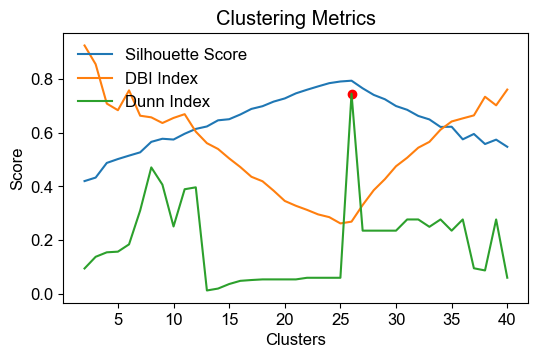

initial: 202.5 69.5
final: 202.5 69.5
initial: 250.0 240.0
final: 250.0 240.0
initial: 85.27272727272727 189.27272727272728
final: 85.27272727272727 189.27272727272728
initial: 66.0 102.0
final: 66.0 102.0
initial: 158.0 268.0
final: 158.0 268.0
initial: 288.40000000000003 303.6
final: 288.40000000000003 303.6
initial: 298.57142857142856 172.28571428571428
final: 298.57142857142856 172.28571428571428
initial: 184.0 220.0
final: 184.0 220.0
initial: 140.0 50.0
final: 140.0 50.0
initial: 42.80000000000001 22.0
final: 42.80000000000001 22.0
initial: 161.0 131.66666666666669
final: 161.0 131.66666666666669
initial: 224.0 150.0
final: 224.0 150.0
initial: 284.2857142857143 90.57142857142858
final: 284.2857142857143 90.57142857142858
initial: 99.45454545454545 244.54545454545456
final: 99.45454545454545 244.54545454545456
initial: 314.3636363636364 259.45454545454544
final: 322.3636363636364 259.45454545454544
initial: 46.00000000000003 178.8
final: 46.00000000000003 178.8
initial: 148.0 210

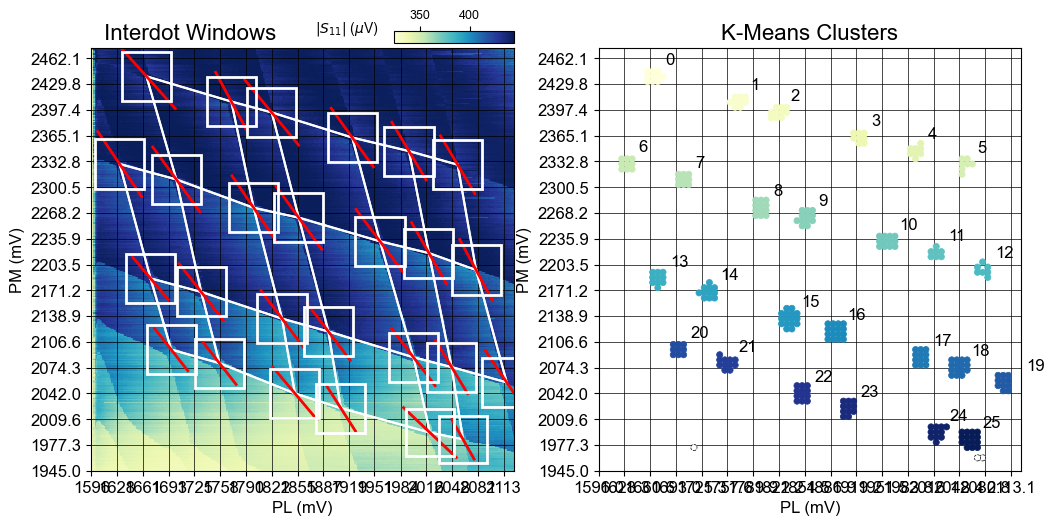

In [27]:
# Retrieve above measurement
initialise_or_create_database_at(r"dataset_name.db")
dataset = qcodes.dataset.load_by_id(###)

data_dict = dataset.get_parameter_data()['z_0']
Z, X, Y = data_dict.values()

x_dac = np.unique(X)
y_dac = np.unique(Y)
x_middle = x_dac.mean()
y_middle = y_dac.mean()
points = len(x_dac)
scan_size = max(x_dac)-min(x_dac)
scan_params = (x_middle, y_middle, scan_size, points)
stability_diagram = np.reshape(Z, (len(y_dac), len(x_dac)))


stride = 4
neighborhood_radius = np.sqrt(8) * stride
min_neighbors = 4
min_clusters = 2
max_clusters = 40
min_population = 1 + min_neighbors
max_population = (20/stride)**2 - 2
threshold = 0.78
model = '../models/Interdot_CNN_model.pth'
filtered_data, cluster_centers, cluster_labels, interdot_centers, discarded_data = run_interdot_finder(stability_diagram, scan_params, stride, threshold, neighborhood_radius, min_neighbors, min_clusters, max_clusters, min_population, max_population, model)

angle_ranges = [
    [135, 180],
    [90, 135],
    [270, 315],
    [315, 360]
]

interdot_centers, cluster_labels = relabel_interdots(interdot_centers, cluster_labels)
nearest_neighbors = nearest_in_angle_ranges(interdot_centers, angle_ranges)
midpoints = find_midpoints_of_neighbors(interdot_centers, nearest_neighbors)
midpoints = improve_midpoints(midpoints, interdot_centers)
midpoints = handle_empty_midpoints(interdot_centers, midpoints, nearest_neighbors)
window_sizes = get_scan_ranges(interdot_centers, extent=0.7)  # 0.5 to be halfway to next transition (or up to opx limit)
pulse_lengths, pulse_points = get_pulse_lengths(interdot_centers, midpoints, extent=0.5)  # 1 to be to the middle of the charge region (or up to opx limit)

print('Number of interdots found:', len(cluster_centers))


fig, axes = plt.subplots(1, 2, figsize=(12, 6))
title = axes[0].set_title('Interdot Windows', fontsize=16, loc='left')
title.set_position([0.03, 1.05])  # [horizontal, vertical]
c = axes[0].pcolormesh(x_dac, y_dac, stability_diagram * 1e6, cmap=cmap)
cbar_ax = fig.add_axes([0.377, 0.855, 0.1, 0.02]) 
cbar = fig.colorbar(c, cax=cbar_ax, orientation='horizontal')
cbar.ax.set_ylabel(r'$|S_{11}|$ ($\mu$V)', rotation=0, labelpad=34, fontsize=10)
cbar.ax.tick_params(labelsize=9)
cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.xaxis.set_label_position('top')

axes[1].set_title('K-Means Clusters', fontsize=16)
if len(discarded_data) > 0:
    axes[1].scatter(discarded_data[:, 0], discarded_data[:, 1], marker='o', facecolor='white', edgecolor='k', s=20, alpha=1, ls='--', lw=0.5, zorder=3)
axes[1].scatter(filtered_data[:, 0], filtered_data[:, 1], c=cluster_labels, marker='o', s=20, cmap=cmap, lw=0.5, zorder=4) # edgecolor='k'
for i, ((x_mid, y_mid), window_size) in enumerate(zip(interdot_centers, window_sizes)):
    rect = plt.Rectangle((x_mid - window_size/2, y_mid - window_size/2), window_size, window_size, linewidth=2, edgecolor='white', facecolor='none', zorder=5)
    axes[0].add_patch(rect)
    axes[1].text(x_mid+15, y_mid+15, f'{i}')

axes[0].set_xticks(np.round(np.arange(scan_params[0]-scan_params[2]/2, scan_params[0]+scan_params[2]/2 + 1, scan_params[2]/scan_params[3] * 20)))
axes[0].set_yticks(np.arange(scan_params[1]-scan_params[2]/2, scan_params[1]+scan_params[2]/2 + 1, scan_params[2]/scan_params[3] * 20))
axes[0].grid(which='both', color='black', linestyle='-', linewidth=0.5, zorder=2)
axes[1].set_xticks(np.arange(scan_params[0]-scan_params[2]/2, scan_params[0]+scan_params[2]/2 + 1, scan_params[2]/scan_params[3] * 20))
axes[1].set_yticks(np.arange(scan_params[1]-scan_params[2]/2, scan_params[1]+scan_params[2]/2 + 1, scan_params[2]/scan_params[3] * 20))
axes[1].grid(which='both', color='black', linestyle='-', linewidth=0.5, zorder=2)
axes[0].set_xlim(scan_params[0]-scan_params[2]/2, scan_params[0]+scan_params[2]/2)
axes[0].set_ylim(scan_params[1]-scan_params[2]/2, scan_params[1]+scan_params[2]/2)
axes[1].set_xlim(scan_params[0]-scan_params[2]/2, scan_params[0]+scan_params[2]/2)
axes[1].set_ylim(scan_params[1]-scan_params[2]/2, scan_params[1]+scan_params[2]/2)
axes[0].set_aspect('equal')
axes[1].set_aspect('equal')
axes[0].set_xlabel('PL (mV)')
axes[0].set_ylabel('PM (mV)')
axes[1].set_xlabel('PL (mV)')
axes[1].set_ylabel('PM (mV)')


for i, point in enumerate(interdot_centers):
    # Iterate over each range and check if a neighbor exists
    for j, neighbor in enumerate(nearest_neighbors[i]):
        # Only plot if a neighbor exists (i.e., not None)
        if neighbor is not None:
            # Plot the line between the current point and its neighbor
            axes[0].plot([point[0], neighbor[0]], [point[1], neighbor[1]], 'w-', alpha=1)

for i, pulse_point_pair in enumerate(pulse_points):
    axes[0].plot(
        [pulse_point_pair[0][0], pulse_point_pair[1][0]],
        [pulse_point_pair[0][1], pulse_point_pair[1][1]],
        c='r', lw=2
    )

plt.show()

# Full Run of Routine

In [ ]:
virts_sensor.vPL(1800)
virts_sensor.vPM(2250)
virts_sensor.vBL(1505)
virts_sensor.vB12(600)
virts_sensor.vB23(455)
SP(2504)

B_PSB_search = -2.5e-3 # T
B_outplane.field(B_PSB_search)

c_matrices = []
paths_barrier = []  # paths across different interdots
paths_scores = []
paths_coordinates = []
paths_best_coordinates = []
rabi_attempts = []


for interdot_number, DC_point in enumerate(interdot_centers):

    initialise_or_create_database_at(r"autonomous_run_interdot_{}.db".format(interdot_number))
    # Go to interdot (always physical value)
    virts_sensor.vPL(DC_point[0])
    virts_sensor.vPM(DC_point[1])
    sleep(1)

    save2db = True

    # Get and save starting gate values for setting them back at the end of the loop
    gate_values_start = []
    for gate_VParam in list_gates:
        gate_values_start.append(gate_VParam.get())

    # check for IDT, then virtualise barriers if present
    passed_virtualisation_step = virtualise_barriers(interdot_number, virts)
    if not passed_virtualisation_step:
        print('Resetting voltages to starting configuration...')
        print(f'BL: {gate_values_start[6]}, B12: {gate_values_start[8]}, B23: {gate_values_start[10]}, PL: {gate_values_start[7]}, PM: {gate_values_start[9]}')
        for gate_VParam, gate_start in zip(list_gates, gate_values_start):
            gate_VParam(gate_start)
        print(f'Going to interdot {interdot_number + 1}')
        continue

    vBL_start = virts.vBL()
    vBL_lower = vBL_start - 20
    vBL_upper = vBL_start + 90
    
    vB12_start = virts.vB12()
    vB12_lower = vB12_start - 90
    vB12_upper = vB12_start + 80
    
    vB23_start = virts.vB23()
    vB23_lower = vB23_start - 60
    vB23_upper = vB23_start + 80

    n_samples = 40
    l_bounds = [vBL_lower, vB12_lower, vB23_lower]
    u_bounds = [vBL_upper, vB12_upper, vB23_upper]

    # This lists are filled inside objective
    path_vBL = [] # values of gate
    path_vB12 = [] # values of gate
    path_vB23 = [] # values of gate
    path_GlobalScore = [] # Global PSB scores (across all pairs of points) 
    path_LocalScores = [] # Local scores of each point
    path_PairScores = [] # Scores of each pair
    path_PairOutcomes = []  # Outcomes based on MLE
    path_GlobalOutcomes = []  # Overall outcome avaeraged across sampling pairs
    path_oscillations = [] # Boolean result of 1D traces of ST oscillations
    path_R2 = [] # R-squared values
    path_hasFreqComponent = [] # Boolean of freq. components
    IDT_list = []  # middle of interdot
    BS_list = []  # bottom triangle samples (plunger DC points)
    TS_list = []  # top triangle samples (plunger DC points)
    PO_list = []  # pulse offsets used by each sample point
    best_point_list = [] # DC physical coordinates, and position of PSB (bottom or top), of plunger pair with the best score
    last_good_config = gate_values_start.copy()  # last voltage set-points for which a good measurement was acquired
    filter_mask_list = [] # List of outliers and valid measurements
    
    iteration = 0
    accumulated_BIC = None
    Qubit = False  # only changed if stopping criteria are met
    promising_idx = None  # updated, if present, after exploration stage

    try:
        result_explore = explore(n_samples, l_bounds, u_bounds, interdot_number)
        print('Maximum exploratory iterations reached, no PSB found.')
    
    except StopIteration as stop:
        print('Qubit found during random search!')
        Qubit = True
    
    if not Qubit:
        # specify conditions and see if a promising candidate exists
        path_PairOutcomes_no_outliers = [(path_PairOutcomes)[ii]*filter_mask_list[ii] for ii in range(len(path_PairOutcomes))]  # outlier outcomes become No PSB
        path_PairScores_no_outliers = [(path_PairScores)[ii]*filter_mask_list[ii] for ii in range(len(path_PairScores))]  # outlier scores become zero
    
        condition1 = np.array(path_hasFreqComponent) # Frequency component detected
        path_R2_floats = np.array(path_R2)
        path_R2_floats[path_R2_floats == None] = 0
        condition2 = np.array(path_R2_floats) > 0.35  # R^2 fitted at least 0.35
        # At least a quarter of outcomes are top or bottom PSB (excluding outliers)
        frac_top_psb = np.array([np.sum(np.where(np.array(path_PairOutcomes_no_outliers[i]) == 1)[1] == 1) / len(path_PairOutcomes_no_outliers[i]) > 0.25 for i in range(len(path_PairOutcomes))])
        frac_bot_psb = np.array([np.sum(np.where(np.array(path_PairOutcomes_no_outliers[i]) == 1)[1] == 2) / len(path_PairOutcomes_no_outliers[i]) > 0.25 for i in range(len(path_PairOutcomes))])
        condition3 = frac_top_psb | frac_bot_psb
        condition4 = np.array(path_GlobalScore) > 0.05  # Score is at least 0.05 (excluding outliers)
        
        # take promising candidate as point with oscillations, if there are multiple, take the one with highest score
        if np.any(condition1 & condition2):
            if np.sum(condition1 & condition2) > 1:
                oscillation_indices = np.where(condition2 & condition1)[0]
                highest_scores_by_iteration = np.max(np.abs(path_PairScores_no_outliers), axis=1).flatten()
                scores_at_oscillation_indices = highest_scores_by_iteration[np.where(condition2 & condition1)[0]]  # use scores of pairs at which oscillation measurement was taken
                promising_idx = np.where(np.array(highest_scores_by_iteration) == np.max(scores_at_oscillation_indices))[0][0] 
            else:
                promising_idx = np.where(condition1 & condition2)[0][0]
    
        # if no oscillations, optimise about point with most promising outcomes, if there are multiple, take the one with highest score
        elif np.any(condition3 & condition4):
            if np.sum(condition3 & condition4) > 1:
                PSB_indices = np.where(condition3 & condition4)[0]
                scores_at_PSB_indices = np.array(path_GlobalScore)[np.where(condition3 & condition4)[0]]
                promising_idx = np.where(np.array(path_GlobalScore) == np.max(scores_at_PSB_indices))[0][0]
            else:
                promising_idx = np.where(condition3 & condition4)[0][0]

    # enter into optimisation if promising candidate exists
    if promising_idx is not None:
        print('Entering into optimisation about most promising candidate...')
        vBL_start, vB12_start, vB23_start = path_vBL[promising_idx], path_vB12[promising_idx], path_vB23[promising_idx]
        x0 = [vBL_start, vB12_start, vB23_start]
        bounds = [(vBL_start-30, vBL_start+30), (vB12_start-30, vB12_start+30), (vB23_start-30, vB23_start+30)]  # bounds of params to be changed
        xatol = 2.0  # virtual voltage tolerance within which result is converged
        fatol = 0.2  # range in scores at simplex vertices below which convergence is met
        maxiter = 10  # maximum number of optimiser moves, increments every n function evaluations, where n+1 is simplex size
        maxfev = 21  # maximum number of objective function evaluations
        # Initial simplex: Each row represents a vertex of the simplex
        vBL_strata, vB12_strata, vB23_strata = 20, 20, 20
        initial_simplex = np.array([
            [vBL_start,              vB12_start,               vB23_start],          # Starting point
            [vBL_start,              vB12_start + vB12_strata, vB23_start + vB23_strata],      # Change in vBL
            [vBL_start - vBL_strata, vB12_start - vB12_strata, vB23_start],      # Change in vB12
            [vBL_start + vBL_strata, vB12_start,               vB23_start  - vB23_strata]       # Change in vB23
        ])
        initial_simplex = check_simplex_bounds(initial_simplex, bounds)
        options = {'maxiter': maxiter, 'maxfev': maxfev, 'xatol': xatol, 'fatol': fatol, 'initial_simplex': initial_simplex}

        # set voltages to promising settings to avoid relying on virtualisation in the objective, barriers are set there again to these same values
        best_vBL = path_vBL[promising_idx]
        best_vB12 = path_vB12[promising_idx]
        best_vB23 = path_vB23[promising_idx]
        best_IDT_PL = IDT_list[promising_idx][0]
        best_IDT_PM = IDT_list[promising_idx][1]
        virts.vBL(best_vBL)
        virts.vB12(best_vB12)
        virts.vB23(best_vB23)
        PL(best_IDT_PL)
        PM(best_IDT_PM)
        
        try:
            result_opt = minimize(objective, x0=x0, args=(interdot_number), method='nelder-mead', bounds=bounds, options=options)
            print('PSB not found.')
        
        except StopIteration as stop:
            print('Qubit found during optimisation!')
            Qubit = True

    # Save best points and do ST oscillations
    if Qubit:  # use parameters of last iteration, which caused optimisation loop to break
        osc_true =  np.array([index for index, value in enumerate(path_oscillations) if value == True], dtype=int)
        max_score_with_osc = np.nanmax([path_GlobalScore[i] for i in osc_true])
        best_setting_idx = np.where(path_GlobalScore==max_score_with_osc)[0][0]
        best_vBL = path_vBL[best_setting_idx]
        best_vB12 = path_vB12[best_setting_idx]
        best_vB23 = path_vB23[best_setting_idx]
        best_PL = best_point_list[best_setting_idx][0][0]
        best_PM = best_point_list[best_setting_idx][0][1]
        pos = best_point_list[best_setting_idx][1]
        best_IDT_PL = IDT_list[best_setting_idx][0]
        best_IDT_PM = IDT_list[best_setting_idx][1]
        pulse_offsets = PO_list[best_setting_idx]
        ST_osc = path_oscillations[best_setting_idx]
    
        paths_barrier.append([interdot_number, path_vBL, path_vB12, path_vB23])
        paths_scores.append([interdot_number, path_GlobalScore, path_LocalScores, path_PairScores])
        paths_coordinates.append([BS_list, TS_list, PO_list])
        paths_best_coordinates.append([interdot_number, best_setting_idx, best_vBL, best_vB12, best_vB23, best_PL, best_PM, pos, pulse_offsets, ST_osc])
        rabi_attempts.append([interdot_number, path_oscillations])
        
        # Set up acquistion of ST trace by re-callibrating sample point at optimal configuration
        print(f'Setting BL to {best_vBL}, a difference of {best_vBL - vBL_start} from the initial point')
        print(f'Setting B12 to {best_vB12}, a difference of {best_vB12 - vB12_start} from the initial point')
        print(f'Setting B23 to {best_vB23}, a difference of {best_vB23 - vB23_start} from the initial point')
        virts.vBL(best_vBL)
        virts.vB12(best_vB12)
        virts.vB23(best_vB23)
        PL(best_IDT_PL)
        PM(best_IDT_PM)
        
        x_middle_phys = PL()
        y_middle_phys = PM()
        
        # # #########################################################################################
        # Code to include the study of oscillation frequency as function of gates
        # Virtualize again around the PSB point
        passed_virtualization_step = virtualise_barriers(interdot_number, virts)
        
        # Find interval where there are oscillations
        interval_BL, interval_B12, interval_B23 = run_bounds_search(best_vBL, best_vB12, best_vB23)
        
        steps = 36
        field_range = 20e-3
        steps_voltage = 5
        steps_detuning = 20
        
        # Oscillations at initial point
        x = [best_vBL, best_vB12, best_vB23]
        # print(x)
        _, bottom_samples, top_samples, distances = voltage_manager(x, window_sizes[interdot_number], pulse_lengths[interdot_number])
        
        # set the gates to that point for best pos
        if pos==0:
            virts_sensor.vPL(bottom_samples[0][0])
            virts_sensor.vPM(bottom_samples[0][1])
        elif pos==1:
            virts_sensor.vPL(top_samples[0][0])
            virts_sensor.vPM(top_samples[0][1])
            
        # Scan 2D vs B
        # Will ramp B field down, then collect traces on the ramp back up
        Bfields, idle_durations, signals = SToscillations_vs_Bout(B_PSB_search, steps, field_range, pulse_offsets, pos)       
        detunings, idling_times, signals = SToscillations_vs_detuning(steps_detuning, pulse_offsets, pos)
        
        # Sweep the other gates
        run_measurements(pos, B_PSB_search, steps, field_range, steps_detuning, [best_vBL, best_vB12, best_vB23, best_IDT_PL, best_IDT_PM], interval_BL, interval_B12, interval_B23)

    # Plot evolution in voltage space
    vBL_bounds = (vBL_lower, vBL_upper)
    vB23_bounds = (vB23_lower, vB23_upper)
    vB12_bounds = (vB12_lower, vB12_upper)
    plot_voltage_space(path_vBL, path_vB23, path_vB12, path_oscillations, vBL_bounds, vB23_bounds, vB12_bounds)
    
    # Set gates to the values of the first iteration
    print('Resetting voltages to starting configuration...')
    print(f'BL: {gate_values_start[6]}, B12: {gate_values_start[8]}, B23: {gate_values_start[10]}, PL: {gate_values_start[7]}, PM: {gate_values_start[9]}')
    for gate_VParam, gate_start in zip(list_gates, gate_values_start):
      gate_VParam(gate_start)
    
    print(f'Going to interdot {interdot_number + 1}')

print('Routine finished!')